# Fixing errors in the iteration-7 research record: the counting-sort relabel (item 0a)

**Artifact:** `eval.py` of `art_vjtPMtWGMjsB` (iteration 8, Step 0). The research question is how algorithm choice, a proxy for "creativity", is represented inside an LLM (Qwen3-8B writing Python programs). It also asks whether prompt bans, context, or activation edits (DAS subspaces, i.e. learned low-rank directions in the residual stream) can move that choice. Step 0 is an **erratum and re-derivation pass** over the iteration-7 report. It answers all 11 items (0a–0k) of a blocking review. Every corrected number is traced to a raw file (`corrections.json`: recorded value, recomputed value, status), and the report is patched with 84 machine-checked edits.

**What this notebook runs:** the stage that carries the headline correction, **item 0a**, on the real data (all 960 kth-smallest programs of exp33):

1. **A1–A2. Extend and validate the labeller.** The frozen kth-smallest labeller sent *counting sort in dictionary form* (`count = {}` … `for v in sorted(count): k -= count[v]`) to `other`. One AST recogniser is added, and it is validated **before** any relabel: 6 bench references, the 28-program gold set (kappa must not drop), and 5 constructed controls.
2. **A3. Relabel** all 960 kth-smallest programs: 35 transitions, all `other → counting_sort`.
3. **A4. Adjudicate** the 42 kth-smallest programs in cells with more than 20% `other`: rule label, two gated LLM judges (labels cached in the data), and manual reads where they disagree.
4. **A5. Recompute** exp33's *pooled recovery* (the share of the full-state activation-swap effect that a rank-k DAS subspace edit recovers) with exp33's own slot bootstrap. A placebo comes first: under the old labels the port must reproduce exp33's published numbers.
5. **Item 0a**: the value ledger (recorded vs recomputed: MATCH / CORRECTED / NEW) and the report edits. Then the independent **headline check** (a regex relabel of the raw program text).

**Headline:** pooled kth-smallest recovery falls from **1.59 / 1.57 / 1.55** to **1.01 / 1.00 / 0.99** at DAS ranks 1 / 4 / 16. The iteration-7 claim that a subspace edit "recovers 1.6× the full-state effect" was a labelling artefact.

| `eval.py` stage | what it does | in this notebook |
|-|-|-|
| `s0` | vendors the 1.3 MB iteration-7 report, hashes every input, lints the report | not run (the report is not shipped) |
| `a` | A1–A5 above | **run** |
| `b` … `k` | items 0a–0k: traced values + report edits | **item 0a run**; 0b–0k read six other iteration-7 artifacts |
| `apply` | applies all 84 edits, writes the diff, lint after, placebo | not run (needs every item and the report) |
| `audit` | independent re-derivations (`audit/rederive.py`, `audit/headline_check.py`) | **headline checks H1–H2 run** |
| `out` | writes `eval_out.json` | replaced by the summary cells at the end |

CPU only, well under a minute, no API calls.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru: NOT pre-installed on Colab, always install (the version eval.py pinned)
_pip('loguru==0.7.3')

# numpy, matplotlib: pre-installed on Colab; install locally only, at Colab's exact versions
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'matplotlib==3.10.0')

In [2]:
from __future__ import annotations

# --- eval.py's own import block (unchanged) ---
import argparse
import json
import resource
import subprocess
import sys
import time
from pathlib import Path
from typing import Any

from loguru import logger

# --- imports of the section modules that eval.py calls (inlined in this notebook) ---
import ast
import hashlib
import math
import random
import re
from collections import Counter, defaultdict
from concurrent.futures import ThreadPoolExecutor
from types import SimpleNamespace

import numpy as np

# --- for the summary and the figures ---
import matplotlib.pyplot as plt

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_jSassd-YWLVC/round-8/evaluation-7/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
print(data["metadata"]["description"])
print(f'{data["metadata"]["n_cells"]} arm cells, {data["metadata"]["n_rows"]} programs')

GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found
Iteration-8 record repair, item 0a (the counting-sort relabel of kth smallest): every exp33 T03 program grouped by arm cell, with the inputs that eval.py stage 'a' reads.
82 arm cells, 960 programs


### What is in `mini_demo_data.json`

One dataset, `kth_smallest_T03_cells`: the 960 kth-smallest programs that Qwen3-8B wrote in exp33, for task **T03**, `solve(nums, k)`, which returns the k-th smallest value. They are grouped into their **82 arm cells**, one example per cell, with 30 (or 4) slots each. The slots are CRN-matched: slot *i* uses the same random seed in every cell. Arm names:

- `BASE_*`: unedited generation (`BASE_W5`: the ban prompt; `BASE_PAD`: the padded twin of a forcing prompt);
- `FULL_*`: the **full-state exchange**, where the whole residual stream at layer 16 is swapped in from a source prompt;
- `DASLY_*_k{r}`: the **rank-r DAS subspace** edit; `RAND_*` and `PERMLY_*` are its random-subspace and permuted-label controls;
- the source is either the ban prompt (`ban`) or a prompt that forces one algorithm (`F_quickselect`, `F_counting_sort`).

Each slot carries exp33's stored fields: `label`, `passed` (hidden tests), `labeller_source`, and the stored `runtime_label` / `ast_label`. `trace` holds the runtime labels of the sandboxed tracer, which runs each program on probe inputs, under the old and the v2 rules. The tracer itself is not shipped. The 42 adjudicated programs also carry the cached labels of judges A and B.

**Program text** is shipped for the 11 cells this notebook relabels live (the counting-sort cells and the placebo cells of the headline check). The metadata holds exp33's kth-smallest configuration, its published pooled recovery (for the placebo), and the labeller-validation inputs. It also holds the numbers the full run produced, for the comparison at the end.

In [5]:
META = data["metadata"]
CELLS = data["datasets"][0]["examples"]

# exp33's data/labels.jsonl rows, one per program, in the file's order (the original reads them from the exp33 workspace)
T03_ROWS = sorted(({**s, "task": c["task"], "arm": c["arm"]} for c in CELLS for s in c["slots"]), key=lambda r: r["row_index"])
# cached judge labels of the adjudicated programs (the original reads them from audit/judge_cache.jsonl)
JUDGE_BY_SID = {r["sample_id"]: r["judge"] for r in T03_ROWS if "judge" in r}

print(f"{len(T03_ROWS)} programs in {len(CELLS)} cells; program text for {sum('code' in r for r in T03_ROWS)}; "
      f"cached judge labels for {len(JUDGE_BY_SID)}")
print("old label counts:", dict(Counter(r["label"] for r in T03_ROWS).most_common()))
for c in CELLS:
    if c["arm"] in ("BASE_PAD", "FULL_F_counting_sort", "DASLY_F_counting_sort_k16"):
        print(f'  {c["arm"]:<26} n={c["n_slots"]}  old labels: {dict(Counter(s["label"] for s in c["slots"]))}')

960 programs in 82 cells; program text for 252; cached judge labels for 42
old label counts: {'quickselect': 454, 'full_sort': 275, 'counting_sort': 118, 'size_k_heap': 40, 'other': 35, 'heapify_pop': 21, 'median_of_medians': 15, 'invalid': 2}
  BASE_PAD                   n=30  old labels: {'full_sort': 30}
  DASLY_F_counting_sort_k16  n=30  old labels: {'counting_sort': 30}
  FULL_F_counting_sort       n=30  old labels: {'other': 29, 'quickselect': 1}


### Configuration

- `STAGES` replaces `eval.py`'s `--stages` argument.
- `BOOT` is the number of resamples in exp33's slot-cluster bootstrap, which gives every pooled-recovery 95% interval. exp33 and the original run use **2000**. The A5 placebo reproduces exp33's published intervals exactly only at 2000; with fewer resamples it compares the point estimates only. `boot_ci` needs at least 100 resamples to report an interval.
- `N_WORKERS` is the labelling thread count (12 in the original, where each program is traced in a subprocess).

In [6]:
# ---- tunable parameters ---------------------------------------------------------------------------------------
STAGES = "a,audit"  # eval.py --stages (original default "all" = s0,a,b..k,apply,audit,out); the demo data feeds a + audit
BOOT = 2000         # slot-bootstrap resamples per 95% interval (= exp33 / original; minimum that yields an interval: 100)
N_WORKERS = 1       # labelling threads (original: 12 for the sandboxed tracer; 1 here, see the labeller cells)

## `eval.py`: setup

This is the original header, nearly unchanged. `ROOT` is now a scratch folder, `eval_demo_run/`, next to the notebook; the original uses the folder that holds `eval.py`. The run writes the same intermediate files there: `results/*.json`, `tables/*.csv`, `audit/*.json` and `logs/run.log`. The `from sections import ...` lines are gone, because the section modules are inlined in the cells below.

In [7]:
ROOT = Path("eval_demo_run").resolve()  # original: Path(__file__).resolve().parent
(ROOT / "logs").mkdir(parents=True, exist_ok=True)
logger.remove()
logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")
logger.add(ROOT / "logs" / "run.log", rotation="30 MB", level="DEBUG")

ALL = ["s0", "a", "b", "c", "d", "e", "f", "g", "h", "i", "j", "k", "apply", "audit", "out"]
ITEM_STAGES = {"a": "0a", "b": "0b", "c": "0c", "d": "0d", "e": "0e", "f": "0f", "g": "0g", "h": "0h", "i": "0i",
               "j": "0j", "k": "0k"}


def _limit_memory(gb: float = 16.0) -> None:
    b = int(gb * 1024 ** 3)
    resource.setrlimit(resource.RLIMIT_AS, (b * 3, b * 3))

## Shared helpers (`sections/common.py`)

These are the parts of the shared module that stage `a` and item 0a use:
- `clopper_pearson` is an exact binomial interval computed from a hand-written incomplete beta function (stdlib only).
- `cohen_kappa` measures agreement between two labellers.
- `value()` records one traced number for the ledger: the value as recorded in the report, the value recomputed from raw data, and a status of MATCH, CORRECTED, NEW or CARRIED. A MATCH outside its tolerance stops the run.
- `edit()` records one machine-checkable report edit.

The original's `dep()` read files from the iteration-7 workspaces; those reads now come from `data`.

In [8]:
RESULTS = ROOT / "results"
TABLES = ROOT / "tables"
AUDIT = ROOT / "audit"
READ_DATE = "2026-10-23"

# artifact id -> folder name under ITER7 (declared dependencies plus the evaluation read by absolute path)
ARTIFACTS = {
    "art_veI9l_Rb9wDY": "gen_art_experiment_33",
    "art_pHL7LWNhpcCS": "gen_art_experiment_34",
    "art_MZAfDPVhM6Ui": "gen_art_experiment_35",
    "art_8O5eaNc5gxJs": "gen_art_experiment_36",
    "art_VhaHGe7SxV95": "gen_art_experiment_37",
    "art_HY7uYZz-OjRW": "gen_art_experiment_38",
    "art_LzP2qPwUrANz": "gen_art_evaluation_6",
}
SHORT = {"art_veI9l_Rb9wDY": "exp33", "art_pHL7LWNhpcCS": "exp34", "art_MZAfDPVhM6Ui": "exp35",
         "art_8O5eaNc5gxJs": "exp36", "art_VhaHGe7SxV95": "exp37", "art_HY7uYZz-OjRW": "exp38",
         "art_LzP2qPwUrANz": "eval6"}
BY_SHORT = {v: k for k, v in SHORT.items()}


def src_ref(short: str, rel: str, key: str = "") -> str:
    """Source string '<artifact_id>:<relative path>#<key>' used in every correction record."""
    return f"{BY_SHORT[short]}:{rel}" + (f"#{key}" if key else "")


def sha256_text(s: str) -> str:
    return hashlib.sha256(s.encode("utf-8")).hexdigest()


def read_json(p: Path) -> Any:
    return json.loads(Path(p).read_text())


def write_json(p: Path, obj: Any) -> None:
    p = Path(p)
    p.parent.mkdir(parents=True, exist_ok=True)
    p.write_text(json.dumps(obj, indent=1, ensure_ascii=False, default=_default))


def _default(o: Any) -> Any:
    if isinstance(o, (set, frozenset)):
        return sorted(o)
    if hasattr(o, "item"):
        return o.item()
    raise TypeError(f"not serialisable: {type(o)}")


def write_csv(p: Path, rows: list[dict[str, Any]], cols: list[str] | None = None) -> None:
    import csv
    p = Path(p)
    p.parent.mkdir(parents=True, exist_ok=True)
    cols = cols or (list(rows[0].keys()) if rows else [])
    with p.open("w", newline="") as f:
        w = csv.DictWriter(f, fieldnames=cols, extrasaction="ignore")
        w.writeheader()
        for r in rows:
            w.writerow({k: ("" if r.get(k) is None else r.get(k)) for k in cols})


# ------------------------------------------------------------------------------------------------ exact statistics
def _betacf(a: float, b: float, x: float) -> float:
    MAXIT, EPS, FPMIN = 300, 3e-16, 1e-300
    qab, qap, qam = a + b, a + 1.0, a - 1.0
    c, d = 1.0, 1.0 - qab * x / qap
    d = 1.0 / (d if abs(d) > FPMIN else FPMIN)
    h = d
    for m in range(1, MAXIT + 1):
        m2 = 2 * m
        aa = m * (b - m) * x / ((qam + m2) * (a + m2))
        d = 1.0 + aa * d
        d = 1.0 / (d if abs(d) > FPMIN else FPMIN)
        c = 1.0 + aa / c
        c = c if abs(c) > FPMIN else FPMIN
        h *= d * c
        aa = -(a + m) * (qab + m) * x / ((a + m2) * (qap + m2))
        d = 1.0 + aa * d
        d = 1.0 / (d if abs(d) > FPMIN else FPMIN)
        c = 1.0 + aa / c
        c = c if abs(c) > FPMIN else FPMIN
        de = d * c
        h *= de
        if abs(de - 1.0) < EPS:
            break
    return h


def betainc(a: float, b: float, x: float) -> float:
    """Regularised incomplete beta I_x(a, b)."""
    if x <= 0.0:
        return 0.0
    if x >= 1.0:
        return 1.0
    lbt = math.lgamma(a + b) - math.lgamma(a) - math.lgamma(b) + a * math.log(x) + b * math.log(1.0 - x)
    bt = math.exp(lbt)
    if x < (a + 1.0) / (a + b + 2.0):
        return bt * _betacf(a, b, x) / a
    return 1.0 - bt * _betacf(b, a, 1.0 - x) / b


def beta_ppf(q: float, a: float, b: float) -> float:
    lo, hi = 0.0, 1.0
    for _ in range(200):
        mid = (lo + hi) / 2
        if betainc(a, b, mid) < q:
            lo = mid
        else:
            hi = mid
    return (lo + hi) / 2


def clopper_pearson(k: int, n: int, alpha: float = 0.05) -> list[float]:
    if n == 0:
        return [float("nan"), float("nan")]
    lo = 0.0 if k == 0 else beta_ppf(alpha / 2, k, n - k + 1)
    hi = 1.0 if k == n else beta_ppf(1 - alpha / 2, k + 1, n - k)
    return [lo, hi]


def cohen_kappa(a: list[str], b: list[str]) -> float:
    n = len(a)
    if n == 0:
        return float("nan")
    po = sum(x == y for x, y in zip(a, b)) / n
    ca, cb = Counter(a), Counter(b)
    pe = sum(ca[k] * cb.get(k, 0) for k in ca) / (n * n)
    if pe >= 1.0:
        return 1.0 if po == 1.0 else 0.0
    return (po - pe) / (1 - pe)


def fmt(x: float | None, nd: int = 2) -> str:
    if x is None or (isinstance(x, float) and math.isnan(x)):
        return "-"
    return f"{x:.{nd}f}"


# ------------------------------------------------------------------------------------------------ correction records
VALUES: list[dict[str, Any]] = []


def value(name: str, recorded: Any, recomputed: Any, status: str, source: str, tolerance: float | str = 0.005,
          item: str = "", note: str = "") -> dict[str, Any]:
    """One traced value: recorded (as printed in current_report.md), recomputed (from the raw file), status in
    MATCH | CORRECTED | NEW | CARRIED. MATCH requires |recorded - recomputed| <= tolerance for numbers."""
    assert status in ("MATCH", "CORRECTED", "NEW", "CARRIED"), status
    rec = {"name": name, "item": item, "recorded": recorded, "recomputed": recomputed, "status": status,
           "tolerance": tolerance, "source": source}
    if note:
        rec["note"] = note
    if status == "MATCH" and isinstance(recorded, (int, float)) and isinstance(recomputed, (int, float)):
        assert abs(float(recorded) - float(recomputed)) <= float(tolerance) + 1e-12, (name, recorded, recomputed)
    VALUES.append(rec)
    return rec


def auto_status(recorded: float | None, recomputed: float, tol: float = 0.005) -> str:
    if recorded is None:
        return "NEW"
    return "MATCH" if abs(recorded - recomputed) <= tol + 1e-12 else "CORRECTED"


SUFFIX = " (iteration-8 correction)"


def edit(cid: str, item: str, section: str, old: str, new: str, kind: str = "prose", why: str = "",
         values: list[str] | None = None) -> dict[str, Any]:
    """One machine-checkable edit of the report. Prose edits must end with the iteration-8 suffix."""
    return {"id": cid, "item": item, "section": section, "kind": kind, "old_text": old, "new_text": new, "why": why,
            "value_names": values or []}

## The kth-smallest labeller (`labeller_v2/ast_rules_v2.py`)

Every program gets two labels:
- a **runtime** label, from tracing its execution on probe inputs in a sandbox (which arrays get sorted, heap operations, dictionary sizes, ...);
- a **static AST** label, from its syntax tree.

`F` collects the AST features of one program. It and the helper predicates below are frozen bench code, copied unchanged.

In [9]:
# Iteration-8 copy of the frozen AST rules for T03_kth_smallest with ONE added recogniser (counting sort, dictionary form -> counting_sort); every other rule is byte-identical to the vendored bench snapshot.
"""Static (AST) labeller: imports, call names, loop/recursion structure, characteristic expressions;
identifier hints are weak evidence only.  ast_label(task, code) -> mode | 'other' | 'unknown' | 'invalid'."""


class F:
    """AST feature bag of one program."""

    def __init__(self, code: str):
        self.code = code
        self.tree = ast.parse(code)
        self.calls = Counter()
        self.attr_calls = Counter()
        self.imports = set()
        self.names = Counter()
        self.funcs = {}
        self.recursive = set()
        self.max_loop_depth = 0
        self.n_loops = 0
        self.classes = 0
        self.decorators = Counter()
        self.bitand_neg = False
        self.pop0 = 0
        self.pop_noarg = 0
        self.popleft = 0
        self.subscript_nested = 0
        self.consts = Counter()
        for node in ast.walk(self.tree):
            if isinstance(node, ast.Import):
                for a in node.names:
                    self.imports.add(a.name.split(".")[0])
            elif isinstance(node, ast.ImportFrom):
                if node.module:
                    self.imports.add(node.module.split(".")[0])
                for a in node.names:
                    self.imports.add(a.name)
            elif isinstance(node, ast.Call):
                fn = node.func
                if isinstance(fn, ast.Name):
                    self.calls[fn.id] += 1
                elif isinstance(fn, ast.Attribute):
                    self.attr_calls[fn.attr] += 1
                    if isinstance(fn.value, ast.Name):
                        self.calls[f"{fn.value.id}.{fn.attr}"] += 1
                    if fn.attr == "pop":
                        if not node.args:
                            self.pop_noarg += 1
                        elif isinstance(node.args[0], ast.Constant) and node.args[0].value == 0:
                            self.pop0 += 1
                    if fn.attr == "popleft":
                        self.popleft += 1
            elif isinstance(node, ast.Name):
                self.names[node.id] += 1
            elif isinstance(node, (ast.FunctionDef, ast.AsyncFunctionDef)):
                self.funcs[node.name] = node
                for d in node.decorator_list:
                    dn = d.func if isinstance(d, ast.Call) else d
                    nm = dn.attr if isinstance(dn, ast.Attribute) else (dn.id if isinstance(dn, ast.Name) else "?")
                    self.decorators[nm] += 1
                for sub in ast.walk(node):
                    if isinstance(sub, ast.Call) and isinstance(sub.func, ast.Name) and sub.func.id == node.name:
                        self.recursive.add(node.name)
                    if isinstance(sub, ast.Call) and isinstance(sub.func, ast.Attribute) and sub.func.attr == node.name:
                        self.recursive.add(node.name)
            elif isinstance(node, ast.ClassDef):
                self.classes += 1
            elif isinstance(node, ast.BinOp) and isinstance(node.op, ast.BitAnd):
                for side in (node.left, node.right):
                    if isinstance(side, ast.UnaryOp) and isinstance(side.op, ast.USub):
                        self.bitand_neg = True
            elif isinstance(node, ast.Subscript) and isinstance(node.slice, ast.Subscript):
                self.subscript_nested += 1
            elif isinstance(node, ast.Constant) and isinstance(node.value, (int, str)):
                self.consts[node.value] += 1
        self._loop_depth(self.tree, 0)
        self.low = code.lower()
        self.idents = {n.lower() for n in self.names} | {f.lower() for f in self.funcs}

    def _loop_depth(self, node, d):
        for ch in ast.iter_child_nodes(node):
            if isinstance(ch, (ast.For, ast.While)):
                self.n_loops += 1
                self.max_loop_depth = max(self.max_loop_depth, d + 1)
                self._loop_depth(ch, d + 1)
            elif isinstance(ch, (ast.FunctionDef, ast.Lambda, ast.AsyncFunctionDef, ast.ClassDef)):
                self._loop_depth(ch, 0)
            else:
                self._loop_depth(ch, d)

    def has(self, *names):
        return any(self.calls.get(n) or self.attr_calls.get(n) for n in names)

    def ident(self, *subs):
        return any(any(s in i for s in subs) for i in self.idents)

    def rx(self, pattern):
        return re.search(pattern, self.code) is not None

    @property
    def memo(self):
        return bool(self.decorators.get("lru_cache") or self.decorators.get("cache") or self.ident("memo", "cache"))


def _bisect(f):
    return f.has("bisect_left", "bisect_right", "bisect", "insort", "insort_left", "insort_right")


def _manual_bsearch(f):
    return f.ident("mid") and f.rx(r"while\s+\w+\s*(<|<=)\s*\w+")


def _uf(f):
    return (f.ident("parent", "root") and (f.ident("find") or "find" in f.funcs)) or f.ident("union", "dsu", "disjoint")


def _heapish(f):
    return f.has("heappush", "heappop", "heapify", "heappushpop", "heapreplace", "nlargest", "nsmallest") or \
        f.has("PriorityQueue")

### The iteration-8 extension: counting sort in dictionary form

This is the one recogniser added in iteration 8, with its helper. A program is labelled `counting_sort` when it does all of the following:
- builds a frequency map over the input values (`Counter(nums)`, `defaultdict(int)`, or `{}` filled with `m[x] = m.get(x, 0) + 1`);
- walks the map in sorted key order, accumulating counts until rank k (or expanding value × count into a list);
- never sorts the whole input and never uses a heap.

The frozen rules sent these programs to `unknown` (AST) and `other` (runtime). In the full-state exchange of the forced counting-sort source, 23 of the 30 slots wrote exactly this program:

```python
def solve(nums, k):
    count = {}
    for num in nums:
        count[num] = count.get(num, 0) + 1
    sorted_nums = sorted(count.keys())
    for num in sorted_nums:
        if k <= count[num]:
            return num
        k -= count[num]
    return -1
```

In [10]:
# ------------------------------------------------------------------------------------------------ iteration-8 extension
def _freq_maps(f):
    """Names bound to a frequency map over the input values: Counter(<input>), defaultdict(int) or a dict literal /
    dict() that the program fills with m[x] = m.get(x, 0) + 1 or m[x] += 1 (iteration-8 extension)."""
    direct, cand, counted = set(), set(), set()
    for node in ast.walk(f.tree):
        if isinstance(node, ast.Assign) and len(node.targets) == 1 and isinstance(node.targets[0], ast.Name):
            nm, v = node.targets[0].id, node.value
            if isinstance(v, ast.Call):
                fn = v.func
                fname = fn.id if isinstance(fn, ast.Name) else (fn.attr if isinstance(fn, ast.Attribute) else "")
                if fname == "Counter" and v.args:
                    direct.add(nm)
                elif fname == "defaultdict" and v.args and isinstance(v.args[0], ast.Name) and v.args[0].id == "int":
                    cand.add(nm)
                elif fname == "dict" and not v.args:
                    cand.add(nm)
            elif isinstance(v, ast.Dict) and not v.keys:
                cand.add(nm)
        elif isinstance(node, ast.AugAssign) and isinstance(node.op, ast.Add) and \
                isinstance(node.target, ast.Subscript) and isinstance(node.target.value, ast.Name):
            counted.add(node.target.value.id)
        elif isinstance(node, ast.Assign) and len(node.targets) == 1 and isinstance(node.targets[0], ast.Subscript) \
                and isinstance(node.targets[0].value, ast.Name):
            nm = node.targets[0].value.id
            src = ast.unparse(node.value).replace(" ", "")
            if f"{nm}.get(" in src and src.endswith("+1"):
                counted.add(nm)
    return direct | (cand & counted)


def _dict_counting_sort(f):
    """Counting sort in dictionary form: a frequency map over the input values, iteration over sorted(map),
    sorted(map.keys()) or sorted(map.items()) (or the sorted distinct values) accumulating counts until rank k, or
    expansion of value x count into a list; no sort of the whole input list and no heap."""
    maps = _freq_maps(f)
    if not maps or _heapish(f) or "solve" not in f.funcs:
        return False
    args = f.funcs["solve"].args.args
    inp = args[0].arg if args else "nums"
    sorts_map = False
    for node in ast.walk(f.tree):
        if not isinstance(node, ast.Call):
            continue
        fn = node.func
        if isinstance(fn, ast.Attribute) and fn.attr == "sort" and isinstance(fn.value, ast.Name) and fn.value.id == inp:
            return False  # sorts the whole input list
        if isinstance(fn, ast.Name) and fn.id == "sorted" and node.args:
            a0 = node.args[0]
            if isinstance(a0, ast.Name) and a0.id == inp:
                return False  # sorted(<input>)
            if any(kw.arg == "key" for kw in node.keywords):
                kv = ast.unparse([kw for kw in node.keywords if kw.arg == "key"][0].value)
                if "[1]" in kv or "get" in kv:
                    continue  # sorted by count, not by value
            if isinstance(a0, ast.Name) and a0.id in maps:
                sorts_map = True
            elif isinstance(a0, ast.Call) and isinstance(a0.func, ast.Attribute) and a0.func.attr in ("keys", "items") \
                    and isinstance(a0.func.value, ast.Name) and a0.func.value.id in maps:
                sorts_map = True
            elif isinstance(a0, ast.Call) and isinstance(a0.func, ast.Name) and a0.func.id == "set" and a0.args and \
                    isinstance(a0.args[0], ast.Name) and a0.args[0].id == inp:
                sorts_map = True  # sorted distinct values walked against the frequency map
    if not sorts_map:
        return False
    walks = f.rx(r"\bk\s*-=") or f.rx(r"(>=|<=|<|>)\s*k\b") or f.rx(r"\bk\s*(>=|<=|<|>)") or \
        f.rx(r"\[\s*\w+\s*\]\s*\*\s*\w+") or f.rx(r"\.extend\(") or f.rx(r"\[\s*k\s*-\s*1\s*\]")
    return bool(walks)

### The kth-smallest rule and the dispatcher

`t03` is the frozen rule plus a two-line hook, marked `iteration-8 extension`. In the module, `RULES` dispatches 13 bench tasks; only kth smallest (`T03`) is needed here.

The frozen (v1) rules are byte-identical to v2 except for that hook. This was checked against the bench snapshot, on every shipped program, when the demo data was built. So `ast_v1` below is v2 with the recogniser switched off; the original imports the frozen bench module for it instead. The switch rebinds a global, which is not thread-safe; that is why `N_WORKERS = 1`.

In [11]:
def t03(f):
    if f.has("nsmallest", "nlargest"):
        return "size_k_heap"
    if f.has("heapify") and f.has("heappop") and not (f.has("heappush") and f.rx(r"len\(\s*\w+\s*\)\s*>")):
        return "heapify_pop"
    if f.has("heappush", "heappushpop", "heapreplace"):
        if f.rx(r"len\(\s*\w+\s*\)\s*(>|>=|==|<|<=)\s*k") or f.has("heappushpop", "heapreplace"):
            return "size_k_heap"
        if f.has("heappop"):
            return "heapify_pop"
    if f.rx(r"\b5\b") and (f.ident("median", "group", "chunk") or f.rx(r":\s*\w+\s*\+\s*5\]")) and f.recursive | {"x"}:
        if f.ident("median") or f.rx(r"range\([^)]*,\s*5\)"):
            return "median_of_medians"
    if f.rx(r"\[0\]\s*\*\s*\(?\s*(max|hi|high|max_val|maxv|mx|\w+_max|20001|20000|10001)") or \
            (f.ident("count") and f.rx(r"\[0\]\s*\*\s*\(") and f.has("min", "max")) or \
            f.rx(r"for\s+\w+\s+in\s+range\(\s*(min|lo|low|min_val|mn|-\s*10000|offset)\w*") and f.ident("count", "freq"):
        return "counting_sort"
    if _dict_counting_sort(f):  # iteration-8 extension: counting sort, dictionary form (maps to counting_sort)
        return "counting_sort"
    if (f.has("Counter") or f.ident("count", "freq")) and f.rx(r"sorted\(\s*\w+\.?(keys|items)?\(?\)?\s*\)"):
        return "unknown"
    if f.ident("pivot", "partition", "quickselect", "select") and not f.has("sort", "sorted"):
        return "quickselect"
    if f.ident("pivot") and f.recursive:
        return "quickselect"
    if f.has("sorted", "sort") and not f.ident("pivot"):
        return "full_sort"
    if f.ident("pivot"):
        return "quickselect"
    return "unknown"


# the module maps 13 bench tasks (T03, T04, ..., R6) to their rules; the demo labels kth smallest only
RULES = {"T03": t03}


def ast_label(task: str, code: str | None) -> str:
    if not code:
        return "invalid"
    try:
        f = F(code)
    except (SyntaxError, ValueError):
        return "invalid"
    if "solve" not in f.funcs:
        return "invalid"
    try:
        return RULES[task](f)
    except (RecursionError, KeyError, TypeError):
        return "unknown"


ast_rules_v2 = SimpleNamespace(ast_label=ast_label)  # stands in for `from labeller_v2 import ast_rules_v2`


def ast_v1(task: str, code: str | None) -> str:
    """The frozen bench rule (original: `from bench.common.astrules import ast_label as ast_v1`): the v2 rules above
    with the iteration-8 recogniser switched off."""
    global _dict_counting_sort
    v2_rule, _dict_counting_sort = _dict_counting_sort, (lambda f: False)
    try:
        return ast_label(task, code)
    finally:
        _dict_counting_sort = v2_rule

In [12]:
# A first look: one program from four cells, with its stored label and its labels under the frozen (v1) and the
# extended (v2) rules (AST labels recomputed here; runtime labels from the stored sandbox trace)
for arm in ("FULL_F_counting_sort", "DASLY_F_counting_sort_k16", "FULL_F_quickselect", "BASE_W5"):
    r = next(x for x in T03_ROWS if x["arm"] == arm)
    print(f"=== {arm}, slot {r['slot_index']}: stored label {r['label']!r} | AST v1 {ast_v1('T03', r['code'])!r} -> "
          f"v2 {ast_rules_v2.ast_label('T03', r['code'])!r} | runtime v1 {r['trace']['rt_v1']!r} -> v2 {r['trace']['rt_v2']!r}")
    print(r["code"])

=== FULL_F_counting_sort, slot 0: stored label 'other' | AST v1 'unknown' -> v2 'counting_sort' | runtime v1 'other' -> v2 'counting_sort'
def solve(nums, k):
    count = {}
    for num in nums:
        count[num] = count.get(num, 0) + 1
    sorted_nums = sorted(count.keys())
    for num in sorted_nums:
        if k <= count[num]:
            return num
        k -= count[num]
    return -1

=== DASLY_F_counting_sort_k16, slot 0: stored label 'counting_sort' | AST v1 'counting_sort' -> v2 'counting_sort' | runtime v1 'counting_sort' -> v2 'counting_sort'
def solve(nums, k):
    def counting_sort(arr):
        min_val = min(arr)
        max_val = max(arr)
        count = [0] * (max_val - min_val + 1)
        for num in arr:
            count[num - min_val] += 1
        sorted_arr = []
        for i in range(len(count)):
            sorted_arr.extend([i + min_val] * count[i])
        return sorted_arr

    sorted_nums = counting_sort(nums)
    return sorted_nums[k - 1]

=== FULL_F_quicks

## Stage A1–A3: validate the extension, then relabel (`sections/a_labeller.py`)

`combine` is exp33's bench rule for joining the two labels. The runtime label goes first; where it is `unknown`, or where a known AST label disagrees, the program is flagged for adjudication.

**A2 validation, run before any relabel.** It checks three things:
- the 6 bench reference programs: both labels must equal the reference's class;
- the 28-program gold set: runtime-vs-AST kappa and runtime-vs-adjudicated agreement must not drop below exp33's recorded `gate.json`;
- 5 constructed controls. The 2 positives (dictionary-form counting sorts) must become `counting_sort`. The 3 negatives must keep their class: a dict memo followed by `sorted(nums)`, a value-bucket select, and a heap over Counter items.

The relabel goes ahead only if all three hold.

**A3** relabels all 960 programs. As a placebo, the old rules recomputed here must reproduce every stored label.

Notebook changes:
- The original `trace_labels(code)` runs the bench tracer in a `python3.12 -I -S` sandbox, which is not shipped. `trace_labels(code, trace)` takes the tracer's runtime labels from the data and **recomputes the AST labels live** whenever the program text is shipped; otherwise it uses the AST labels stored by the full run.
- The controls' hidden-test results (`run_tests`, 60 cases) also come from the data.

In [13]:
"""labeller_v2/controls.py (unchanged). Executor-written validation controls for the dictionary-form counting-sort
extension (STEP A2 iii-iv).

Two positive controls (they must become counting_sort) and three negative controls (they must keep their class).
The two positives double as the 'constructed dictionary-form counting sorts' of the judge gate (STEP A4); they are
executor-constructed because the bench holds no independent exemplar of that form (a declared partial departure)."""

POSITIVE = {
    "pos_counter_cumulative": (
        "counting_sort",
        "from collections import Counter\n\n"
        "def solve(nums, k):\n"
        "    cnt = Counter(nums)\n"
        "    seen = 0\n"
        "    for v in sorted(cnt):\n"
        "        seen += cnt[v]\n"
        "        if seen >= k:\n"
        "            return v\n",
    ),
    "pos_dict_items_expand": (
        "counting_sort",
        "def solve(nums, k):\n"
        "    freq = {}\n"
        "    for x in nums:\n"
        "        freq[x] = freq.get(x, 0) + 1\n"
        "    out = []\n"
        "    for v, c in sorted(freq.items()):\n"
        "        out.extend([v] * c)\n"
        "    return out[k - 1]\n",
    ),
}

NEGATIVE = {
    # a dict used only as a memo, then a full sort of the input: must stay full_sort
    "neg_memo_then_full_sort": (
        "full_sort",
        "def solve(nums, k):\n"
        "    memo = {}\n"
        "    for x in nums:\n"
        "        if x not in memo:\n"
        "            memo[x] = abs(x)\n"
        "    return sorted(nums)[k - 1]\n",
    ),
    # value buckets of fixed width, recursing into the bucket that holds rank k: must stay other (no bucket class)
    "neg_bucket_select": (
        "other",
        "def solve(nums, k):\n"
        "    vals, lo, span = nums, -10000, 20001\n"
        "    while True:\n"
        "        width = max(1, span // 50)\n"
        "        nb = span // width + 1\n"
        "        buckets = [[] for _ in range(nb)]\n"
        "        for x in vals:\n"
        "            buckets[(x - lo) // width].append(x)\n"
        "        for i, b in enumerate(buckets):\n"
        "            if k <= len(b):\n"
        "                vals, lo = b, lo + i * width\n"
        "                break\n"
        "            k -= len(b)\n"
        "        if width == 1:\n"
        "            return vals[0]\n"
        "        span = width\n",
    ),
    # a heap over the (value, count) items of a Counter: must stay a heap class
    "neg_heap_over_counter": (
        "heapify_pop",
        "import heapq\n"
        "from collections import Counter\n\n"
        "def solve(nums, k):\n"
        "    items = list(Counter(nums).items())\n"
        "    heapq.heapify(items)\n"
        "    while True:\n"
        "        v, c = heapq.heappop(items)\n"
        "        if k <= c:\n"
        "            return v\n"
        "        k -= c\n",
    ),
}

In [14]:
"""sections/a_labeller.py. STEP A1-A3: the kth-smallest labeller extended to counting sort in dictionary form,
validated on the vendored bench references, the gold set and five constructed controls BEFORE any relabel, then
applied to every T03 row of exp33."""

LV = META["labeller_validation"]  # original: the vendored bench (inputs/bench_T03/) and exp33's gate.json


def trace_labels(code: str | None, trace: dict[str, Any]) -> dict[str, Any]:
    """Old and new runtime and AST labels of one program. Runtime labels: the stored result of the sandboxed bench
    tracer (not shipped); AST labels: recomputed here from the program text whenever it is shipped."""
    if code is None:  # program text not shipped with the demo data: all four labels as stored by the full run
        return dict(trace)
    if not code or "def solve" not in code:
        return {"rt_v1": "invalid", "rt_v2": "invalid", "ast_v1": "invalid", "ast_v2": "invalid"}
    a1, a2 = ast_v1("T03", code), ast_rules_v2.ast_label("T03", code)
    out = {"rt_v1": trace["rt_v1"], "rt_v2": trace["rt_v2"], "ast_v1": a1, "ast_v2": a2}
    if "sig" in trace:  # the tracer's feature signature, kept for the controls
        out["sig"] = trace["sig"]
    return out


def combine(rt: str, ast: str) -> tuple[str, str, bool]:
    """exp33's bench combination (label_worker_v4.label_bench_rows): runtime first; a judge only where the runtime
    label is unknown or a known AST label disagrees; without a judge the fallback is runtime, else AST, else other."""
    if rt == "invalid":
        return "invalid", "extraction", False
    need = rt == "unknown" or (ast != "unknown" and ast != rt)
    if need:
        lab = rt if rt != "unknown" else (ast if ast != "unknown" else "other")
        return lab, "rule_fallback(needs_adjudication)", True
    return rt, ("runtime+ast" if ast == rt else "runtime(ast_unknown)"), False


def _par(fn, xs):
    with ThreadPoolExecutor(N_WORKERS) as ex:
        return list(ex.map(fn, xs))


# ------------------------------------------------------------------------------------------------ A2 validation
def validate() -> dict[str, Any]:
    refs = LV["references"]  # original: sorted((T03_DIR / "references").glob("*.py"))
    gold = LV["gold"]  # original: read_jsonl(T03_DIR / "gold_set.jsonl")
    ref_rows = []
    for p, lab in zip(refs, _par(lambda p: trace_labels(p["code"], p["trace"]), refs)):
        ref_rows.append({"ref": p["ref"], **{k: lab[k] for k in ("rt_v1", "rt_v2", "ast_v1", "ast_v2")}})
    ref_agree_v2 = sum(r["rt_v2"] == r["ref"] and r["ast_v2"] == r["ref"] for r in ref_rows) / len(ref_rows)
    ref_agree_v1 = sum(r["rt_v1"] == r["ref"] and r["ast_v1"] == r["ref"] for r in ref_rows) / len(ref_rows)
    glabs = _par(lambda g: trace_labels(g["code"], g["trace"]), gold)
    g_rows = []
    for g, lab in zip(gold, glabs):
        g_rows.append({"gold_id": g["gold_id"], "source": g["source"], "stored_runtime": g["runtime"],
                       "stored_ast": g["ast"], "adjudicated": g.get("adjudicated"), "known": g.get("known"),
                       **{k: lab[k] for k in ("rt_v1", "rt_v2", "ast_v1", "ast_v2")}})

    def gate(rt_key: str, ast_key: str) -> dict[str, Any]:
        rt = [r[rt_key] for r in g_rows]
        at = [r[ast_key] for r in g_rows]
        adj = [r for r in g_rows if r["adjudicated"]]
        return {"n": len(g_rows), "kappa_runtime_ast": cohen_kappa(rt, at),
                "runtime_vs_adjudicated": sum(r[rt_key] == r["adjudicated"] for r in adj) / len(adj),
                "raw_agreement": sum(a == b for a, b in zip(rt, at)) / len(rt)}

    stored = gate("stored_runtime", "stored_ast")
    old, new = gate("rt_v1", "ast_v1"), gate("rt_v2", "ast_v2")
    gj = META["exp33"]["gate_json_gold"]  # original: read_json(dep("exp33", ".../gate.json"))["gold"]
    ctrl_rows = []
    for name, (want, code) in {**POSITIVE, **NEGATIVE}.items():
        lab = trace_labels(code, LV["control_traces"][name])
        comb2 = combine(lab["rt_v2"], lab["ast_v2"])[0]
        comb1 = combine(lab["rt_v1"], lab["ast_v1"])[0]
        t = LV["control_traces"][name]  # original: run_tests(code, "T03", cases), the 60 hidden tests in the sandbox
        ok = comb2 == want and (name.startswith("pos") or comb2 == comb1)
        ctrl_rows.append({"control": name, "kind": "positive" if name.startswith("pos") else "negative",
                          "expected": want, "rt_v1": lab["rt_v1"], "ast_v1": lab["ast_v1"], "combined_v1": comb1,
                          "rt_v2": lab["rt_v2"], "ast_v2": lab["ast_v2"], "combined_v2": comb2,
                          "passes_hidden_tests": bool(t["passed"]), "n_pass": t["n_pass"], "n_cases": t["n_cases"],
                          "control_pass": bool(ok and t["passed"]), "signature": lab.get("sig")})
    res = {
        "ref_rows": ref_rows, "ref_agreement_v1": ref_agree_v1, "ref_agreement_v2": ref_agree_v2,
        "gold_rows": g_rows, "gold_stored": stored, "gold_old_recomputed": old, "gold_new": new,
        "gate_json_recorded": {k: gj[k] for k in ("kappa_runtime_ast", "runtime_vs_adjudicated", "raw_agreement", "n")},
        "old_reproduces_gate_json": abs(old["kappa_runtime_ast"] - gj["kappa_runtime_ast"]) < 1e-9 and
        abs(old["runtime_vs_adjudicated"] - gj["runtime_vs_adjudicated"]) < 1e-9,
        "controls": ctrl_rows, "controls_pass": sum(r["control_pass"] for r in ctrl_rows),
        "n_controls": len(ctrl_rows),
        "source_gold": src_ref("exp33", "inputs/exp11/bench/T03_kth_smallest/gold_set.jsonl"),
        "source_gate": src_ref("exp33", "inputs/exp11/bench/T03_kth_smallest/gate.json", "gold"),
    }
    res["no_regression"] = (res["ref_agreement_v2"] == 1.0 and new["kappa_runtime_ast"] >= gj["kappa_runtime_ast"] - 1e-9
                            and new["runtime_vs_adjudicated"] >= gj["runtime_vs_adjudicated"] - 1e-9)
    res["relabel_allowed"] = bool(res["no_regression"] and res["controls_pass"] == res["n_controls"])
    logger.info(f"A2: refs v2 {ref_agree_v2:.2f}; gold kappa old {old['kappa_runtime_ast']:.3f} new "
                f"{new['kappa_runtime_ast']:.3f}; rt-vs-adj old {old['runtime_vs_adjudicated']:.3f} new "
                f"{new['runtime_vs_adjudicated']:.3f}; controls {res['controls_pass']}/{res['n_controls']}; "
                f"relabel_allowed={res['relabel_allowed']}")
    write_csv(TABLES / "labeller_v2_validation.csv",
              [{"set": "reference", "id": r["ref"], "expected": r["ref"], **r} for r in ref_rows] +
              [{"set": "gold", "id": r["gold_id"], "expected": r["adjudicated"], **r} for r in g_rows] +
              [{"set": "control", "id": r["control"], **r} for r in ctrl_rows],
              ["set", "id", "expected", "rt_v1", "ast_v1", "rt_v2", "ast_v2", "combined_v1", "combined_v2",
               "passes_hidden_tests", "control_pass"])
    return res


# ------------------------------------------------------------------------------------------------ A3 relabel
def relabel_t03() -> dict[str, Any]:
    rows = [r for r in T03_ROWS if r["task"] == "T03"]  # original: read_jsonl(dep("exp33", "data/labels.jsonl"))
    labs = _par(lambda r: trace_labels(r.get("code"), r["trace"]), rows)
    out = []
    for r, lab in zip(rows, labs):
        if not r.get("valid"):
            new, src, need = "invalid", "extraction", False
        else:
            new, src, need = combine(lab["rt_v2"], lab["ast_v2"])
            same_inputs = (lab["rt_v2"], lab["ast_v2"]) == (r.get("runtime_label"), r.get("ast_label"))
            if need and same_inputs and r["labeller_source"] in ("judge", "runtime_unjudged"):
                new, src, need = r["label"], "carried(" + r["labeller_source"] + ")", False
        out.append({"sample_id": r["sample_id"], "arm": r["arm"], "slot_index": r["slot_index"],
                    "passed": bool(r.get("passed")), "valid": bool(r.get("valid")), "old_label": r["label"],
                    "old_source": r["labeller_source"], "old_runtime": r.get("runtime_label"),
                    "old_ast": r.get("ast_label"), "rt_v1": lab["rt_v1"], "ast_v1": lab["ast_v1"],
                    "rt_v2": lab["rt_v2"], "ast_v2": lab["ast_v2"], "rule_v2": new, "rule_v2_source": src,
                    "needs_adjudication": need, "code_sha256": r.get("code_sha256")})
    # placebo: the old rules recomputed here must reproduce the stored runtime/AST labels of every valid row
    v = [o for o in out if o["valid"]]
    repro_rt = sum(o["rt_v1"] == o["old_runtime"] for o in v) / max(len(v), 1)
    repro_ast = sum(o["ast_v1"] == o["old_ast"] for o in v) / max(len(v), 1)
    conf = Counter((o["old_label"], o["rule_v2"]) for o in out)
    trans = [o for o in out if o["old_label"] != o["rule_v2"]]
    unexpected = [o for o in trans if not (o["old_label"] == "other" and o["rule_v2"] == "counting_sort")]
    write_csv(TABLES / "relabel_confusion.csv",
              [{"old_label": a, "new_label": b, "n": n} for (a, b), n in sorted(conf.items())],
              ["old_label", "new_label", "n"])
    logger.info(f"A3: {len(out)} T03 rows; old rules reproduce stored runtime {repro_rt:.3f} / AST {repro_ast:.3f}; "
                f"{len(trans)} transitions, {len(unexpected)} not other->counting_sort")
    return {"rows": out, "repro_runtime": repro_rt, "repro_ast": repro_ast,
            "confusion": {f"{a}->{b}": n for (a, b), n in sorted(conf.items())},
            "n_transitions": len(trans), "unexpected_transitions": [o["sample_id"] for o in unexpected],
            "source": src_ref("exp33", "data/labels.jsonl", "task==T03")}


def high_other_cells() -> list[dict[str, Any]]:
    """Every exp33 cell (all three tasks in the original; kth smallest here) whose OLD 'other' share exceeds 20%."""
    rows = T03_ROWS  # original: read_jsonl(dep("exp33", "data/labels.jsonl"))
    by: dict[tuple[str, str], Counter] = defaultdict(Counter)
    for r in rows:
        by[(r["task"], r["arm"])][r["label"]] += 1
    cells = []
    for (t, a), c in sorted(by.items()):
        n = sum(c.values())
        if c.get("other", 0) / n > 0.2:
            cells.append({"task": t, "arm": a, "n": n, "n_other": c["other"], "other_share": c["other"] / n,
                          "labels": dict(c)})
    return cells


def run() -> dict[str, Any]:
    val = validate()
    write_json(RESULTS / "a2_validation.json", val)
    if not val["relabel_allowed"]:
        logger.error("A2 validation failed: relabel blocked (one revision round allowed)")
    rel = relabel_t03()
    write_json(RESULTS / "a3_relabel.json", rel)
    cells = high_other_cells()
    write_json(RESULTS / "a3_high_other_cells.json", cells)
    return {"validation": val, "relabel": rel, "cells": cells}


AL = SimpleNamespace(run=run, validate=validate, relabel_t03=relabel_t03, high_other_cells=high_other_cells)

## Stage A4: adjudicate the high-`other` cells (`sections/a_adjudicate.py`, `sections/manual_reads.py`)

Every program in an exp33 cell whose old `other` share exceeds 20% gets an **adjudicated label**. Across the three tasks there are 19 such cells and 162 programs; the 4 kth-smallest cells hold 42 of them. Three readers label each program: the (v2) rule, **judge A** (`deepseek-chat-v3.1`) and **judge B** (`mistral-medium-3.1`).

- The judges see the code blind to its cell, at temperature 0. A judge counts only if it scores at least 9/10 on 10 known-class gate controls (A scored 10/10, B 9/10).
- Where all counted readers agree, the rule label stands.
- Where they disagree, the executor's **manual read** decides. A fixed-seed sample of 10 agreeing programs is also read, as a check.

Notebook changes:
- The judges are not called; their cached labels ship with the data. The full run spent USD 0.095 on judge calls in total.
- `MANUAL` keeps only the 4 kth-smallest reads. The 41 shortest-path reads refer to programs that are not in the demo data.
- The agreement sample was drawn with `random.Random(7)` over all 162 programs, so its kth-smallest part is taken from that recorded draw.

In [15]:
"""sections/manual_reads.py. The executor's manual reads (STEP A4), keyed by the first 12 hex digits of the program's
sha256. One entry per distinct program where the counted readers (rule, judge A, judge B) disagree, plus the
fixed-seed 10-program sample where they agree. Read on 2026-10-23 from tables/counting_sort_adjudication.csv and
logs/manual_queue.txt, blind to the cell's arm outcome counts (the cell name is visible in the queue file).
(Demo: only the 4 kth-smallest entries; the 41 shortest-path entries refer to programs not in the demo data.)"""

MANUAL = {
    # T03 (kth smallest)
    "a2e18e96e898": ("counting_sort", "dictionary form: dict counts, sorted keys walked until k is covered (sample)"),
    "6407f9c6e45f": ("counting_sort", "dict counts walked over the value range min..max, expanded to a list (sample)"),
    "ab79cb14e32d": ("counting_sort", "dictionary form: dict counts, sorted(count.keys()) walked with k -= count (sample)"),
    "5828ba352521": ("other", "binary search on the value range with a count of values <= mid; not quickselect "
                              "(no partition), a known technique outside the catalogue"),
}


def resolve(full_hashes: list[str]) -> dict[str, dict[str, str]]:
    """Map full sha256 -> {label, note} for every prefix above (each prefix must match exactly one hash)."""
    out = {}
    for pre, (lab, note) in MANUAL.items():
        hits = [h for h in full_hashes if h.startswith(pre)]
        if len(hits) != 1:
            raise ValueError(f"manual-read prefix {pre} matches {len(hits)} programs")
        out[hits[0]] = {"label": lab, "note": note}
    return out


MR = SimpleNamespace(resolve=resolve, MANUAL=MANUAL)

In [16]:
"""sections/a_adjudicate.py. STEP A4: the adjudicated column for every program in the exp33 cells whose OLD 'other'
share exceeds 20%: rule label (T03: the validated v2 labeller), judge A, judge B (two families, gated on 10
known-class controls, 9/10 to count), and the executor's manual read of every program where the counted readers
disagree plus a fixed-seed 10-program sample where they agree."""

JUDGES = {"A": "deepseek/deepseek-chat-v3.1", "B": "mistralai/mistral-medium-3.1"}  # sections/judges.py
GATE_MIN = 9


def gate_controls() -> list[dict[str, Any]]:
    ctr = []
    for p in LV["references"]:  # original: sorted((T03_DIR / "references").glob("*.py"))
        ctr.append({"id": f"ref:{p['ref']}", "task": "T03", "known": p["ref"], "code": p["code"], "origin": "bench reference"})
    gold = sorted((g for g in LV["gold"] if g["source"] != "reference"),
                  key=lambda g: g["gold_id"])
    for want in ("quickselect", "size_k_heap"):
        g = next(x for x in gold if x["adjudicated"] == want)
        ctr.append({"id": f"gold:{g['gold_id']}", "task": "T03", "known": want, "code": g["code"], "origin": "gold set"})
    for name, (want, code) in POSITIVE.items():
        ctr.append({"id": f"constructed:{name}", "task": "T03", "known": want, "code": code,
                    "origin": "executor-constructed (dictionary form)"})
    return ctr


def programs(cells: list[dict[str, Any]], relabel_rows: list[dict[str, Any]]) -> list[dict[str, Any]]:
    keep = {(c["task"], c["arm"]) for c in cells}
    v2 = {r["sample_id"]: r for r in relabel_rows}
    out = []
    for r in T03_ROWS:  # original: read_jsonl(dep("exp33", "data/labels.jsonl")), all three tasks
        if (r["task"], r["arm"]) not in keep:
            continue
        rule = v2[r["sample_id"]]["rule_v2"] if r["task"] == "T03" else r["label"]
        out.append({"sample_id": r["sample_id"], "task": r["task"], "cell": r["arm"], "slot_index": r["slot_index"],
                    "passed": bool(r.get("passed")), "valid": bool(r.get("valid")), "old_label": r["label"],
                    "rule_label": rule, "code": r.get("code") or "", "code_sha256": sha256_text(r.get("code") or ""),
                    "finish_reason": r.get("finish_reason")})
    return out


def _cached_judges(ctr: list[dict[str, Any]], progs: list[dict[str, Any]]) -> dict[str, Any]:
    """Stands in for _run_judges(), which sends the 10 gate controls and every distinct program to judges A and B
    through OpenRouter (temperature 0, max_tokens 200, every response cached in audit/judge_cache.jsonl). Here the
    gate scores and the cached labels shipped with the demo data are read back."""
    gate = META["judge_gate"]
    logger.info(f"judge gate: " + ", ".join(f"{k} {v['model']} {v['score']}/{v['n']}" for k, v in gate.items()))
    # distinct programs only: identical code gets the identical label
    distinct = {}
    for p in progs:
        if p["valid"] and p["code"]:
            distinct.setdefault((p["task"], p["code_sha256"]), p)
    order = list(distinct.values())
    random.Random(20261023).shuffle(order)  # blind order: no cell or arm in the prompt, shuffled across cells
    lab = defaultdict(dict)
    for p in order:
        for jn in JUDGES:
            lab[(p["task"], p["code_sha256"])][jn] = JUDGE_BY_SID[p["sample_id"]][jn]
    sp = META["judge_spend"]
    return {"gate": gate, "labels": lab, "spent_usd_this_run": 0.0, "n_calls_this_run": 0,
            "cached_cost_usd": sp["cached_usd"], "refused": False, "key_before": None, "key_after": None,
            "n_distinct": len(order)}


def run(cells: list[dict[str, Any]], relabel_rows: list[dict[str, Any]], manual: dict[str, dict[str, str]]
        ) -> dict[str, Any]:
    ctr = gate_controls()
    progs = programs(cells, relabel_rows)
    jr = _cached_judges(ctr, progs)  # original: asyncio.run(_run_judges(ctr, progs))
    counted = [k for k, v in jr["gate"].items() if v["passes"]]
    rows = []
    for p in progs:
        jl = jr["labels"].get((p["task"], p["code_sha256"]), {})
        a, b = jl.get("A"), jl.get("B")
        readers = [p["rule_label"]] + [jl.get(k) for k in counted]
        agree = p["valid"] and len(set(readers)) == 1 and None not in readers
        rows.append({**{k: p[k] for k in ("sample_id", "task", "cell", "slot_index", "passed", "valid", "old_label",
                                          "rule_label", "code_sha256", "finish_reason")},
                     "judge_A": a, "judge_B": b, "counted_judges": "+".join(counted) or "none", "readers_agree": agree})
    # manual reads: every disagreement among counted readers (or every program when no judge counts) + agreement sample
    agree_rows = [r for r in rows if r["readers_agree"]]
    # original: random.Random(7).sample(agree_rows, min(10, len(agree_rows))), drawn over the agreeing programs of all
    # three tasks; the demo carries kth smallest only, so it takes the kth-smallest part of that recorded draw
    sample = set(r["sample_id"] for r in agree_rows if JUDGE_BY_SID[r["sample_id"]]["in_agreement_sample"])
    need_manual = [r for r in rows if r["valid"] and (not r["readers_agree"] or not counted)]
    for r in rows:
        m = manual.get(r["code_sha256"])
        r["in_agreement_sample"] = r["sample_id"] in sample
        r["manual_read"] = m["label"] if m else None
        r["manual_note"] = m["note"] if m else None
        if not r["valid"]:
            r["final_label"], r["final_source"] = "invalid", "extraction"
        elif r["readers_agree"] and counted:
            r["final_label"], r["final_source"] = r["rule_label"], "rule+" + "+".join(counted)
        elif m:
            r["final_label"], r["final_source"] = m["label"], "manual read"
        else:
            r["final_label"], r["final_source"] = None, "MISSING manual read"
        r["manual_overrides_rule"] = bool(m and r["valid"] and m["label"] != r["rule_label"])
    missing = sorted({r["code_sha256"] for r in rows if r["final_source"] == "MISSING manual read"})
    miss_sample = sorted({r["code_sha256"] for r in rows if r["in_agreement_sample"] and not r["manual_read"]})
    v = [r for r in rows if r["valid"] and r["judge_A"] and r["judge_B"]]
    kap = {"rule_vs_A": cohen_kappa([r["rule_label"] for r in v], [r["judge_A"] for r in v]),
           "rule_vs_B": cohen_kappa([r["rule_label"] for r in v], [r["judge_B"] for r in v]),
           "A_vs_B": cohen_kappa([r["judge_A"] for r in v], [r["judge_B"] for r in v]), "n": len(v)}
    vm = [r for r in rows if r["valid"] and r["manual_read"]]
    rule_vs_manual = sum(r["rule_label"] == r["manual_read"] for r in vm) / max(len(vm), 1)
    final_counts = defaultdict(Counter)
    for r in rows:
        final_counts[r["cell"]][r["final_label"]] += 1
    res = {"gate": jr["gate"], "counted_judges": counted, "kappa": kap, "n_programs": len(rows),
           "n_distinct_judged": jr["n_distinct"], "n_need_manual": len(need_manual),
           "n_manual_reads": len({r["code_sha256"] for r in vm}), "manual_overrides": sum(r["manual_overrides_rule"] for r in rows),
           "rule_vs_manual_agreement": rule_vs_manual, "n_rule_vs_manual": len(vm),
           "missing_manual_codes": missing, "missing_sample_codes": miss_sample,
           "final_counts": {c: dict(v) for c, v in final_counts.items()},
           "spend": {"this_run_usd": jr["spent_usd_this_run"], "cached_usd": jr["cached_cost_usd"],
                     "n_calls_this_run": jr["n_calls_this_run"], "refused": jr["refused"]},
           "key_before": jr["key_before"], "key_after": jr["key_after"],
           "source": src_ref("exp33", "data/labels.jsonl", "cells with old other share > 0.2")}
    write_json(AUDIT / "judge_gate.json", {"controls": [{k: c[k] for k in ("id", "known", "origin")} for c in ctr],
                                           "gate": jr["gate"], "judges": JUDGES, "rule": f">= {GATE_MIN}/10 to count"})
    write_csv(TABLES / "counting_sort_adjudication.csv", rows,
              ["sample_id", "task", "cell", "slot_index", "passed", "valid", "old_label", "rule_label", "judge_A",
               "judge_B", "counted_judges", "readers_agree", "in_agreement_sample", "manual_read", "manual_note",
               "final_label", "final_source", "manual_overrides_rule", "code_sha256"])
    write_json(RESULTS / "a4_adjudication.json", {**res, "rows": rows})
    logger.info(f"A4: {len(rows)} programs, counted judges {counted}, kappa {kap}, need manual {len(need_manual)}, "
                f"missing manual {len(missing)}, spend ${jr['spent_usd_this_run']:.4f} (+cached ${jr['cached_cost_usd']:.4f})")
    return {**res, "rows": rows}


AD = SimpleNamespace(run=run, programs=programs, gate_controls=gate_controls)

## Stage A5: recompute pooled recovery (`sections/a_recompute.py`)

This is a line-for-line port of exp33's `src/analysis7.py` (`p1_task`, `pooled_recovery`, `boot_ci`, routing). A *source* is a prompt pair: a base prompt and a source prompt that drives the model to a target algorithm set *Y*. The **full-state exchange** swaps the whole layer-16 residual stream from the source run into the base run; the **DAS edit** swaps only a learned rank-k subspace. A cell's count is the number of its 30 slots whose program **passes the hidden tests and is labelled in Y**:

$$\text{pooled recovery}(k) \;=\; \frac{\sum_{s}\big(\#\mathrm{DAS}_k(s) - \#\mathrm{base}(s)\big)}{\sum_{s}\big(\#\mathrm{full}(s) - \#\mathrm{base}(s)\big)}$$

1.0 means the subspace edit carries the whole effect of the full-state swap. The 95% interval resamples the 30 CRN **slots** jointly in every cell, using `numpy.default_rng(20261022)` and `BOOT` resamples.

Kth smallest has three sources: the ban prompt (Y = {quickselect, size_k_heap}), and the forcing prompts for quickselect and for counting sort. Under the old labels, the full-state exchange of the forced counting-sort source scored **0 of 30**, because its 29 dictionary-form counting sorts were `other`. That shrank the denominator to 51 and inflated recovery to 81/51 = 1.59. The **placebo** runs first: the port under the old labels must reproduce exp33's published numbers.

In [17]:
"""sections/a_recompute.py. STEP A5: recompute what the relabel touches with exp33's own definitions (a line-for-line
port of exp33 src/analysis7.py p1_task / pooled_recovery / boot_ci / routing: slot-cluster bootstrap, 2,000 resamples,
numpy default_rng(20261022), percentile 2.5/97.5). Placebo first: under the OLD labels the port must reproduce the old
kth smallest values (1.59 / 1.57 / 1.55) and their intervals."""

N = 30
# BOOT (resamples) is set in the config cell; exp33 and the original module use 2000
EXP33_BOOT = 2000
SEED = 20261022
RANKS = (1, 2, 4, 8, 16)
DEFAULT = {"T2": "dijkstra", "T10": "union_find", "T03": "full_sort"}


def load_rows() -> list[dict[str, Any]]:
    return T03_ROWS  # original: read_jsonl(dep("exp33", "data/labels.jsonl")), all three tasks


def arms_of(rows: list[dict[str, Any]], task: str, override: dict[str, str] | None = None
            ) -> dict[str, dict[int, dict[str, Any]]]:
    out: dict[str, dict[int, dict[str, Any]]] = defaultdict(dict)
    for r in rows:
        if r["task"] == task:
            rr = r
            if override and r["sample_id"] in override:
                rr = {**r, "label": override[r["sample_id"]]}
            out[r["arm"]][int(r["slot_index"])] = rr
    return out


def cy(r: dict[str, Any] | None, Y: list[str]) -> int:
    return int(bool(r) and bool(r.get("passed")) and r.get("label") in Y)


def vec(A: dict, arm: str | None, Y: list[str]) -> np.ndarray | None:
    if not arm or arm not in A:
        return None
    return np.array([cy(A[arm].get(s), Y) for s in range(N)])


def pass_rate(A: dict, arm: str) -> float | None:
    if arm not in A:
        return None
    rs = [A[arm].get(s) for s in range(N) if A[arm].get(s)]
    return float(np.mean([bool(r.get("passed")) for r in rs])) if rs else None


def sources(task: str) -> list[dict[str, Any]]:
    # original: exp33 results/targets_{task}.json, kstar_{task}.json and site_{task}.json
    T = META["exp33"][f"targets_{task}"]
    ks = META["exp33"][f"kstar_{task}"]
    site = META["exp33"][f"site_{task}"]
    full = "FULL_ban_band" if site["site"] == "band" else f"FULL_ban_L{site['L_star']}"
    landing = T["landing"] or T["kept_Y"][:1]
    k = ks["k_star"]
    out = [{"name": "ban", "Y": landing, "base": "BASE_W5", "full": full,
            "das": {kk: f"DASLY_ban_k{kk}" for kk in RANKS},
            "rand": {16: ["RAND_ban_k16_d1", "RAND_ban_k16_d2", "RAND_ban_k16_d3"],
                     k: ([f"RAND_ban_k{k}"] if k != 16 else ["RAND_ban_k16_d1", "RAND_ban_k16_d2", "RAND_ban_k16_d3"])},
            "perm": {16: "PERMLY_ban_k16", k: f"PERMLY_ban_k{k}"}}]
    for Y in ks["kept_Y_cells"]:
        out.append({"name": f"F_{Y}", "Y": [Y], "base": "BASE_PAD", "full": f"FULL_F_{Y}",
                    "das": {kk: f"DASLY_F_{Y}_k{kk}" for kk in (1, 4, 16)}, "rand": {16: [f"RAND_F_{Y}_k16"]},
                    "perm": {16: f"PERMLY_F_{Y}_k16"}})
    return out


def pooled_recovery(A: dict, srcs: list[dict[str, Any]], k: int, slots: np.ndarray | None = None,
                    which: str = "das") -> tuple[float | None, float, float]:
    num = den = 0.0
    for s in srcs:
        b, f = vec(A, s["base"], s["Y"]), vec(A, s["full"], s["Y"])
        arms = ([s["das"].get(k)] if s["das"].get(k) else []) if which == "das" else s["rand"].get(k, [])
        vs = [v for v in (vec(A, a, s["Y"]) for a in arms) if v is not None]
        if b is None or f is None or not vs:
            continue
        idx = slots if slots is not None else np.arange(N)
        x = float(np.mean([v[idx].sum() for v in vs]))
        num += x - b[idx].sum()
        den += f[idx].sum() - b[idx].sum()
    return (num / den if den > 0 else None), num, den


def boot_ci(A: dict, srcs: list[dict[str, Any]], k: int, which: str = "das", seed: int = SEED,
            n_boot: int = BOOT) -> list[float | None]:
    rng = np.random.default_rng(seed)
    vals = []
    for _ in range(n_boot):
        idx = rng.integers(0, N, N)
        r, _, _ = pooled_recovery(A, srcs, k, idx, which)
        if r is not None:
            vals.append(r)
    if len(vals) < 100:
        return [None, None]
    return [float(np.percentile(vals, 2.5)), float(np.percentile(vals, 97.5))]

In [18]:
def p1_task(rows: list[dict[str, Any]], task: str, override: dict[str, str] | None = None) -> dict[str, Any]:
    A = arms_of(rows, task, override)
    srcs = sources(task)
    ks = META["exp33"][f"kstar_{task}"]["k_star"]  # original: read_json(dep("exp33", f"results/kstar_{task}.json"))
    out: dict[str, Any] = {"per_k": {}, "per_source": {}}
    for s in srcs:
        b, f = vec(A, s["base"], s["Y"]), vec(A, s["full"], s["Y"])
        if b is None or f is None:
            continue
        ps = {"Y": s["Y"], "base_count": int(b.sum()), "full_count": int(f.sum()),
              "full_transfer": float((f.sum() - b.sum()) / N), "base_pass": pass_rate(A, s["base"]),
              "full_pass": pass_rate(A, s["full"]), "das": {}, "perm": {}, "rand": {}}
        for k, a in s["das"].items():
            v = vec(A, a, s["Y"])
            if v is not None:
                ps["das"][k] = {"count": int(v.sum()), "transfer": float((v.sum() - b.sum()) / N),
                                "recovery": float((v.sum() - b.sum()) / (f.sum() - b.sum())) if f.sum() > b.sum() else None,
                                "pass": pass_rate(A, a), "share_ci": clopper_pearson(int(v.sum()), N)}
        for k, arms in s["rand"].items():
            for a in arms:
                v = vec(A, a, s["Y"])
                if v is not None:
                    ps["rand"][a] = {"count": int(v.sum()), "transfer": float((v.sum() - b.sum()) / N)}
        for k, a in s["perm"].items():
            v = vec(A, a, s["Y"])
            if v is not None:
                ps["perm"][a] = {"count": int(v.sum()), "transfer": float((v.sum() - b.sum()) / N),
                                 "relative_to_full": float((v.sum() - b.sum()) / (f.sum() - b.sum()))
                                 if f.sum() > b.sum() else None}
        out["per_source"][s["name"]] = ps
    cand = sorted({16, ks})
    for k in RANKS:
        r, num, den = pooled_recovery(A, srcs, k)
        rr = pooled_recovery(A, srcs, k, which="rand")[0] if k in cand else None
        e = {"recovery": r, "num": num, "den": den, "recovery_ci": boot_ci(A, srcs, k) if r is not None else None,
             "random_recovery": rr}
        if k in cand:
            perm = []
            for s in srcs:
                a = s["perm"].get(k)
                b, v = vec(A, s["base"], s["Y"]), vec(A, a, s["Y"])
                if v is not None and b is not None:
                    perm.append(float((v.sum() - b.sum()) / N))
            e["permuted_transfer_max"] = max(perm) if perm else None
        out["per_k"][k] = e
    return out


def routing_cell(rows: list[dict[str, Any]], task: str, arm: str, Y: str, override: dict[str, str] | None = None
                 ) -> dict[str, Any]:
    A = arms_of(rows, task, override)
    rs = [A[arm][s] for s in range(N) if s in A.get(arm, {})]
    corr = [r for r in rs if r.get("passed")]
    offd = [r for r in corr if r["label"] != DEFAULT[task]]
    ny = sum(r["label"] == Y for r in corr)
    return {"n": len(rs), "correct_Y": ny, "correct_off_default": len(offd),
            "routing": ny / len(offd) if offd else None, "routing_ci": clopper_pearson(ny, len(offd)) if offd else None,
            "landing": dict(Counter(r["label"] for r in corr)), "fail": len(rs) - len(corr)}


def run(final_map: dict[str, str]) -> dict[str, Any]:
    """final_map: sample_id -> new label for every T03 row (rule_v2, or the adjudicated label where adjudicated)."""
    rows = load_rows()
    p1 = {"T03": META["exp33"]["p1_T03"]}  # original: read_json(dep("exp33", "results/p1.json"))["tasks"]
    res: dict[str, Any] = {"placebo": {}, "old": {}, "new": {}}
    # placebo 1: the port under OLD labels reproduces exp33's per_k (point and CI). The original checks all three tasks
    # (T2, T10, T03); the demo data carries kth smallest only. exp33's CI is only reproducible with its 2,000 resamples,
    # so with a smaller BOOT the placebo compares the point estimates only.
    for t in ("T03",):
        mine = p1_task(rows, t)
        res["old"][t] = mine
        chk = []
        for k in RANKS:
            ex, me = p1[t]["per_k"][str(k)], mine["per_k"][k]
            ok = (ex["recovery"] is None and me["recovery"] is None) or (
                ex["recovery"] is not None and me["recovery"] is not None and abs(ex["recovery"] - me["recovery"]) < 1e-9
                and (ex["recovery_ci"] is None or BOOT != EXP33_BOOT or (
                    abs(ex["recovery_ci"][0] - me["recovery_ci"][0]) < 1e-9 and
                    abs(ex["recovery_ci"][1] - me["recovery_ci"][1]) < 1e-9)))
            chk.append({"k": k, "exp33": [ex["recovery"], ex["recovery_ci"]],
                        "port": [me["recovery"], me["recovery_ci"]], "match": bool(ok)})
        res["placebo"][t] = {"rows": chk, "all_match": all(c["match"] for c in chk)}
    # new labels on kth smallest
    res["new"]["T03"] = p1_task(rows, "T03", final_map)
    res["routing"] = {
        "old_full_counting": routing_cell(rows, "T03", "FULL_F_counting_sort", "counting_sort"),
        "new_full_counting": routing_cell(rows, "T03", "FULL_F_counting_sort", "counting_sort", final_map),
        "new_das_counting": {f"k{k}": routing_cell(rows, "T03", f"DASLY_F_counting_sort_k{k}", "counting_sort", final_map)
                             for k in (1, 4, 16)},
    }
    # 29 of the 36 catalogue variants of 7.3.9 come from FULL_F_counting_sort?
    na = META["exp33"]["novelty_audit"]  # original: read_json(dep("exp33", "results/novelty_audit.json"))
    res["novelty_audit"] = novelty_by_cell(na)
    res["source"] = src_ref("exp33", "data/labels.jsonl") + " + " + src_ref("exp33", "src/analysis7.py", "p1_task")
    return res


def novelty_by_cell(na: Any) -> dict[str, Any]:
    """Count the novelty-audit programs (correct, labelled other) by source cell and final class."""
    items = None
    if isinstance(na, dict):
        for k in ("items", "programs", "rows", "audited", "results"):
            if isinstance(na.get(k), list):
                items = na[k]
                break
    if items is None:
        return {"error": "no item list found", "keys": list(na.keys()) if isinstance(na, dict) else None}
    by = Counter()
    by_cls = Counter()
    for it in items:
        cell = it.get("arm") or it.get("cell") or (it.get("sample_id", "").split("|")[1] if "|" in it.get("sample_id", "") else None)
        cls = it.get("final_class") or it.get("class") or it.get("verdict") or it.get("label")
        by[(it.get("task"), cell)] += 1
        by_cls[(cell, cls)] += 1
    return {"n": len(items), "by_cell": {f"{t}|{c}": n for (t, c), n in by.most_common()},
            "by_cell_class": {f"{c}|{k}": n for (c, k), n in by_cls.most_common()}}


RC = SimpleNamespace(run=run, p1_task=p1_task, pooled_recovery=pooled_recovery, boot_ci=boot_ci, routing_cell=routing_cell)

## `eval.py`: stage `a`, the context loader and `_int_keys`

`stage_a()` is unchanged apart from its `from sections import ...` line; `AL`, `AD`, `MR` and `RC` are the cells above. It chains A1–A5 with three hard stops:
1. the relabel is blocked unless the A2 validation passes;
2. every adjudicated program needs its manual read;
3. the A5 placebo must reproduce exp33.

The final label map is the v2 rule label, overridden by the adjudicated label where one exists. Later stages read the whole context back from `results/` through `load_ctx`, exactly as in a staged run.

In [19]:
def stage_a() -> dict[str, Any]:
    # original: from sections import a_adjudicate as AD, a_labeller as AL, a_recompute as RC, manual_reads as MR
    base = AL.run()
    if not base["validation"]["relabel_allowed"]:
        raise RuntimeError("A2 validation failed: the relabel is blocked")
    rel = base["relabel"]["rows"]
    hashes = sorted({r["code_sha256"] for r in AD.programs(base["cells"], rel)})
    adj = AD.run(base["cells"], rel, MR.resolve(hashes))
    if adj["missing_manual_codes"] or adj["missing_sample_codes"]:
        raise RuntimeError(f"manual reads missing for {len(adj['missing_manual_codes'])} + {len(adj['missing_sample_codes'])} programs")
    fmap = {r["sample_id"]: r["rule_v2"] for r in rel}
    for r in adj["rows"]:
        if r["task"] == "T03":
            fmap[r["sample_id"]] = r["final_label"]
    write_json(RESULTS / "final_labels_T03.json", fmap)
    rc = RC.run(fmap)
    for t, v in rc["placebo"].items():
        if not v["all_match"]:
            raise RuntimeError(f"A5 placebo failed on {t}: the port does not reproduce exp33's pooled recovery")
    write_json(RESULTS / "a5_recompute.json", rc)
    return {"a2": base["validation"], "a3": base["relabel"], "a4": adj, "a5": rc}


def load_ctx() -> dict[str, Any]:
    return {"a2": read_json(RESULTS / "a2_validation.json"), "a3": read_json(RESULTS / "a3_relabel.json"),
            "a4": read_json(RESULTS / "a4_adjudication.json"), "a5": _int_keys(read_json(RESULTS / "a5_recompute.json"))}


def _int_keys(o: Any) -> Any:
    """JSON turns the per_k / das rank keys into strings; restore ints where a key is a rank."""
    if isinstance(o, dict):
        return {(int(k) if isinstance(k, str) and k.isdigit() else k): _int_keys(v) for k, v in o.items()}
    if isinstance(o, list):
        return [_int_keys(x) for x in o]
    return o

## Item 0a: traced values and report edits (`sections/item_a.py`)

Every number the report printed that the relabel touches is recorded with `value()`, as recorded in the report vs recomputed here:
- placebo values (old labels) must MATCH;
- corrected values become CORRECTED;
- values the report lacked become NEW.

Every passage to fix becomes an `edit()`: an exact `old_text` → `new_text` pair that the `apply` stage substitutes into the report, where each `old_text` must occur exactly once.

The implementation form is a regex on the program text: an array of counts (`[0] * …`) or a dictionary. It backs the corrected routing claim: on kth smallest, DAS changes the *form* of the counting sort, not the algorithm.

Notebook change: the original's last block, the shortest-path contrastive pilot (Table 301), reads the 120 shortest-path adjudication rows. Those are not in the demo data, so that block is left out.

In [20]:
"""sections/item_a.py. Item 0a: the counting-sort relabel. Edits to 7.3.4, Tables 296, 297, 300, 314, 370, 371, 372,
7.3.6, 7.3.9 and 7.10, each value traced to exp33's raw label rows through the validated v2 labeller and the gated
adjudication."""


def item_a_run(ctx: dict[str, Any]) -> dict[str, Any]:  # original: item_a.run
    rc, adj, val, rel = ctx["a5"], ctx["a4"], ctx["a2"], ctx["a3"]
    S = src_ref("exp33", "data/labels.jsonl", "arm==FULL_F_counting_sort") + " + labeller_v2 + tables/counting_sort_adjudication.csv"
    new = rc["new"]["T03"]
    old = rc["old"]["T03"]
    full_new = new["per_source"]["F_counting_sort"]["full_count"]
    value("T03 forced counting sort: full state correct counting sort (of 30)", 0, full_new, "CORRECTED", S, 0, "0a")
    rec = {}
    for k in (1, 4, 16):
        e, eo = new["per_k"][k], old["per_k"][k]
        rec[k] = e
        value(f"T03 pooled recovery k{k} (old labels, placebo)", round(eo["recovery"], 2), eo["recovery"], "MATCH",
              src_ref("exp33", "results/p1.json", f"tasks.T03.per_k.{k}.recovery"), 0.005, "0a")
        value(f"T03 pooled recovery k{k}", round(eo["recovery"], 2), e["recovery"], "CORRECTED", S, 0.005, "0a",
              f"num {e['num']:.0f} / den {e['den']:.0f}; slot bootstrap 95% [{e['recovery_ci'][0]:.2f}, {e['recovery_ci'][1]:.2f}]")
    rr1, rr16 = new["per_k"][1]["random_recovery"], new["per_k"][16]["random_recovery"]
    value("T03 random-subspace recovery k1 (Table 297)", 0.05, rr1, "MATCH", S, 0.005, "0a",
          "normalised by the full state over the sources that have random arms (ban source only), so the relabel does not touch it")
    value("T03 random-subspace recovery k16 (Table 297)", 0.05, rr16, "MATCH", S, 0.005, "0a")
    pt1, pt16 = new["per_k"][1]["permuted_transfer_max"], new["per_k"][16]["permuted_transfer_max"]
    value("T03 permuted-label transfer k1 (7.3.5)", 0.60, pt1, "MATCH", S, 0.005, "0a",
          "absolute transfer (count - base)/30 of the ban source; not normalised by the full state, so the relabel does not touch it")
    value("T03 permuted-label transfer k16 (Table 297)", 0.47, pt16, "MATCH", S, 0.005, "0a")
    r_old, r_new = rc["routing"]["old_full_counting"], rc["routing"]["new_full_counting"]
    ci = r_new["routing_ci"]
    value("Table 300 kth smallest | counting sort: full state routing", 0.0, r_new["routing"], "CORRECTED", S, 0.005, "0a",
          f"{r_new['correct_Y']}/{r_new['correct_off_default']} [CP {ci[0]:.2f}, {ci[1]:.2f}]")
    na = rc["novelty_audit"]["by_cell_class"]
    n_full = na.get("FULL_F_counting_sort|CATALOGUE_VARIANT", 0)
    n_forced = sum(v for k, v in na.items() if k.startswith(("F1_counting_sort", "F2_counting_sort", "F3_counting_sort")))
    value("7.3.9 catalogue variants from FULL_F_counting_sort (of 36)", None, n_full, "NEW",
          src_ref("exp33", "results/novelty_audit.json", "rows[].arm"), 0, "0a")
    value("7.3.9 catalogue variants from the forced counting sort prompts F1-F3 (of 36)", None, n_forced, "NEW",
          src_ref("exp33", "results/novelty_audit.json", "rows[].arm"), 0, "0a")
    g = adj["gate"]
    value("judge gate A (deepseek-chat-v3.1), of 10", None, g["A"]["score"], "NEW", "audit/judge_gate.json", 0, "0a")
    value("judge gate B (mistral-medium-3.1), of 10", None, g["B"]["score"], "NEW", "audit/judge_gate.json", 0, "0a")
    value("labeller v2: gold kappa runtime-vs-AST", round(val["gate_json_recorded"]["kappa_runtime_ast"], 3),
          val["gold_new"]["kappa_runtime_ast"], "MATCH", val["source_gate"], 0.0005, "0a")
    value("labeller v2: controls passed (of 5)", None, val["controls_pass"], "NEW", "results/a2_validation.json", 0, "0a")

    # implementation form of the counting sorts: array of counts, or a dictionary (sorted keys / walked over the value range)
    form = {}
    for r in T03_ROWS:  # original: read_jsonl(dep("exp33", "data/labels.jsonl"))
        if r["task"] == "T03" and r["arm"] in ("FULL_F_counting_sort", "DASLY_F_counting_sort_k1", "DASLY_F_counting_sort_k4", "DASLY_F_counting_sort_k16"):
            code = r.get("code") or ""
            f = "array" if re.search(r"\[0\]\s*\*", code) else ("dict_sorted_keys" if re.search(r"=\s*\{\}|Counter\(|defaultdict\(int\)|dict\(\)", code) and "sorted(" in code
                                                                else "dict_value_range" if re.search(r"=\s*\{\}|Counter\(|defaultdict\(int\)|dict\(\)", code) else "neither")
            form.setdefault(r["arm"], {}).setdefault(f, 0)
            form[r["arm"]][f] += 1
    for arm, d in sorted(form.items()):
        value(f"counting sort implementation form, {arm}", None, dict(sorted(d.items())), "NEW",
              src_ref("exp33", "data/labels.jsonl", f"arm=={arm} (regex on code)"), "exact", "0a")
    a1, a16 = form["DASLY_F_counting_sort_k1"].get("array", 0), form["DASLY_F_counting_sort_k16"].get("array", 0)
    d16 = 30 - a16
    c = lambda k: f"{rec[k]['recovery']:.2f} [{rec[k]['recovery_ci'][0]:.2f}, {rec[k]['recovery_ci'][1]:.2f}]"
    # the full-state exchange of the forced counting sort source: 29 counting sort (dictionary form) + 1 other
    land = r_new["landing"]
    n_other_full = land.get("other", 0)
    E = []
    E.append(edit("C8-a01", "0a", "7.3.4", "on kth smallest the forced counting sort source transfers 30 of 30 at every rank while the full state exchange gives 0 (29 programs labelled other, read below).",
                  f"on kth smallest the forced counting sort source transfers 30 of 30 at every rank, and the full state exchange of the same prompt gives {full_new} of 30: the 29 programs once labelled other are counting sort in dictionary form (counts in a dictionary walked in sorted key order), which the extended labeller now names counting sort, and the remaining program is a binary search on the value range (Table 300){SUFFIX}.",
                  why="dictionary-form counting sort was labelled other; relabel validated on references, gold set and negative controls"))
    E.append(edit("C8-a02", "0a", "Table 296", "**Table 296.** Kth smallest: correct programs of the target algorithm (of 30) by source and rank.",
                  "**Table 296.** Kth smallest: correct programs of the target algorithm (of 30) by source and rank. (iteration-8 correction: forced counting sort source, full state 0 -> 29 after the labeller was extended to counting sort in dictionary form)", kind="caption"))
    E.append(edit("C8-a03", "0a", "Table 296", "| forced counting sort source | counting sort | 0 | 0 | 30 (pass 1.00) | - | 30 (pass 1.00) | - | 30 (pass 1.00) |  |  | 1.00/1.00 |",
                  f"| forced counting sort source | counting sort | 0 | {full_new} | 30 (pass 1.00) | - | 30 (pass 1.00) | - | 30 (pass 1.00) |  |  | 1.00/1.00 |", kind="table_row"))
    E.append(edit("C8-a04", "0a", "Table 297", "**Table 297.** Kth smallest: pooled recovery and its controls by rank.",
                  "**Table 297.** Kth smallest: pooled recovery and its controls by rank. (iteration-8 correction: pooled recovery recomputed after the counting-sort relabel with exp33's own slot bootstrap, 2,000 resamples; the old values 1.59 / 1.57 / 1.55 are reproduced exactly under the old labels; the permuted-label column is an absolute transfer, (count - base)/30, and the random-subspace recovery uses only the ban source, so neither changes; per-source recovery in Table 297b is the summary)", kind="caption"))
    E.append(edit("C8-a05", "0a", "Table 297", "| 1 | 1.59 [1.47, 1.72] | 0.05 | 20:0 (1.9e-06) | 0.60 | 0.90 |",
                  f"| 1 | {c(1)} | 0.05 | 20:0 (1.9e-06) | 0.60 | 0.90 |", kind="table_row"))
    E.append(edit("C8-a06", "0a", "Table 297", "| 4 | 1.57 [1.44, 1.72] | - | - | - | - |",
                  f"| 4 | {c(4)} | - | - | - | - |", kind="table_row"))
    E.append(edit("C8-a07", "0a", "Table 297", "| 16 | 1.55 [1.42, 1.70] | 0.05 | 21:0 (9.5e-07) | 0.47 | 0.90 |",
                  f"| 16 | {c(16)} | 0.05 | 21:0 (9.5e-07) | 0.47 | 0.90 |", kind="table_row"))
    E.append(edit("C8-a08", "0a", "7.3.6", "and the counting sort source lands on counting sort in 30 of 30 at rank 16 while the full state exchange lands none (Table 300). Connected components is not categorical: the forced BFS source's rank-16 edit lands 21 DFS and 9 BFS. The subspace thus carries which algorithm, and on two tasks it carries it more cleanly than the whole state does.",
                  f"and the counting sort source lands on counting sort in 30 of 30 at rank 16, where the full state exchange of the same prompt also lands {full_new} of 30 on counting sort once its dictionary form is labelled (Table 300). Connected components is not categorical: the forced BFS source's rank-16 edit lands 21 DFS and 9 BFS. The subspace thus carries which algorithm, more cleanly than the full state on one task (shortest path: Floyd-Warshall 28/28 against 8/20); on kth smallest the DAS edit changes the implementation form (mostly an array of counts, {a16} of 30 at rank 16, against the full state's dictionary with sorted keys, {full_new} of 30), not the algorithm{SUFFIX}."))
    E.append(edit("C8-a09", "0a", "Table 300", "**Table 300.** Routing: where correct programs off the default land under the full state exchange and under DAS.",
                  "**Table 300.** Routing: where correct programs off the default land under the full state exchange and under DAS. (iteration-8 correction: kth smallest | counting sort row relabelled; the committed C rule still scores kth smallest categorical, because it reads the DAS columns)", kind="caption"))
    E.append(edit("C8-a10", "0a", "Table 300", "| kth smallest | counting sort | 0.00 (0/30) [0.00, 0.12] | 1.00 (30/30) [0.88, 1.00] | 1.00 (30/30) [0.88, 1.00] | 1.00 (30/30) [0.88, 1.00] | other 29, quickselect 1 | counting sort 30 |",
                  f"| kth smallest | counting sort | {r_new['routing']:.2f} ({r_new['correct_Y']}/{r_new['correct_off_default']}) [{ci[0]:.2f}, {ci[1]:.2f}] | 1.00 (30/30) [0.88, 1.00] | 1.00 (30/30) [0.88, 1.00] | 1.00 (30/30) [0.88, 1.00] | counting sort (dictionary form) {full_new}, binary search on the value range {n_other_full} | counting sort 30 (array of counts {a16}, dictionary walked over the value range {d16}) |", kind="table_row"))
    E.append(edit("C8-a11", "0a", "Table 314", "| kth smallest | full state exchange, forced counting sort source | 30 | 1.00 | 0 | other 29, quickselect 1 |",
                  f"| kth smallest | full state exchange, forced counting sort source | 30 | 1.00 | 0 | counting sort (dictionary form) {full_new}, other {n_other_full} (binary search on the value range; iteration-8 correction) |", kind="table_row"))
    E.append(edit("C8-a12", "0a", "7.3.9", "Of the 38 correct programs labelled other across the experiment, 36 are catalogue variants and 2 are labeller misses; none is novel.",
                  f"Of the 38 correct programs labelled other across the experiment, 36 are catalogue variants and 2 are labeller misses; none is novel. {n_full} of the 36 come from the full state exchange of the forced counting sort source and {n_forced} more from the forced counting sort prompts: they are counting sort in dictionary form, which the extended labeller now names counting sort{SUFFIX}."))
    E.append(edit("C8-a13", "0a", "Table 371", "| DAS experiment | 38 correct programs labelled other | 36 catalogue variants, 2 labeller misses | 0 |",
                  f"| DAS experiment | 38 correct programs labelled other | 36 catalogue variants ({n_full + n_forced} are counting sort in dictionary form, {n_full} of them from the full state exchange of the forced counting sort source; relabelled counting sort in iteration 8), 2 labeller misses | 0 |", kind="table_row"))
    E.append(edit("C8-a16", "0a", "Table 371", "**Table 371.** Novelty audits of iteration 7.",
                  "**Table 371.** Novelty audits of iteration 7. (iteration-8 correction: the DAS experiment row names the counting-sort cells)", kind="caption"))
    E.append(edit("C8-a14", "0a", "Table 372", "| Routing claim | Categorical on shortest path and kth smallest; not on connected components | Floyd-Warshall 28/28 and counting sort 30/30 under DAS; forced BFS lands on DFS |",
                  f"| Routing claim | Categorical by the committed rule on two tasks (shortest path, kth smallest), not on connected components (iteration-8 correction) | Floyd-Warshall 28/28 under DAS against 8/20 for the full state; on kth smallest the full state also lands {full_new} of 30 on counting sort (dictionary form) against 30/30 under DAS ({a16} of them an array of counts); forced BFS lands on DFS |", kind="table_row"))
    E.append(edit("C8-a15", "0a", "Table 370", "| Qwen3-8B, kth smallest | DAS rank 1, forced counting sort source | 30/30 counting sort | 0/30 | 1.00 |",
                  f"| Qwen3-8B, kth smallest | DAS rank 1, forced counting sort source | 30/30 counting sort ({a1} an array of counts; the full state exchange gives {full_new}/30 in dictionary form, iteration-8 correction) | 0/30 | 1.00 |", kind="table_row"))
    # (original: the committed contrastive pilot on shortest path, Table 301, edit C8-a17 and its two values, from the
    #  shortest-path rows of the adjudication; the demo data carries kth smallest only, so that block is not run)
    return {"edits": E, "verdict": "CORRECTED",
            "summary": {"forms": form, "full_state_counting_sort": full_new, "kth_pooled_recovery": {k: rec[k]["recovery"] for k in rec},
                        "kth_pooled_recovery_ci": {k: rec[k]["recovery_ci"] for k in rec},
                        "catalogue_variants_from_full_cell": n_full, "from_forced_prompts": n_forced}}

## `eval.py`: running the item stages and writing the ledger

- `run_items` runs each requested item stage, attaches the values it recorded, and writes `results/item_0a.json`. The original maps all eleven items `a`–`k`; here only `a` has its inputs.
- `write_corrections` writes `corrections.json`: every edit plus the value ledger. The original calls it inside the `apply` stage, after all eleven items; here it is called once, after `main()`, on item 0a alone.

In [21]:
def run_items(stages: list[str], ctx: dict[str, Any]) -> dict[str, Any]:
    # original: from sections import item_a, item_b, item_cde, item_f, item_ghijk, and fn maps all eleven items a-k;
    # items 0b-0k read six more iteration-7 artifacts (exp34-exp38, eval6), which the demo data does not carry
    fn = {"a": item_a_run}
    out = {}
    for s in stages:
        if s in fn:
            t0 = time.time()
            n0 = len(VALUES)
            r = fn[s](ctx)
            r["values"] = VALUES[n0:]
            out[ITEM_STAGES[s]] = r
            write_json(RESULTS / f"item_{ITEM_STAGES[s]}.json", r)
            logger.info(f"item {ITEM_STAGES[s]}: {len(r['edits'])} edits, {len(r['values'])} values ({time.time() - t0:.1f}s)")
    return out


def write_corrections(items: dict[str, Any], s0: dict[str, Any], ap: dict[str, Any]) -> dict[str, Any]:
    edits = [e for it in items.values() for e in it["edits"]]
    vals = [v for it in items.values() for v in it["values"]]
    by_status = {s: sum(v["status"] == s for v in vals) for s in ("MATCH", "CORRECTED", "NEW", "CARRIED")}
    corr = {"read_date": READ_DATE, "report_sha256": s0["hashes"]["report"]["sha256"] if s0 else None,
            "schema": "mirrors art_LzP2qPwUrANz corrections.json: one record per edit (old_text occurs once in the vendored report) plus a value ledger",
            "n_edits": len(edits), "n_values": len(vals), "values_by_status": by_status,
            "n_edits_by_item": {k: len(v["edits"]) for k, v in items.items()},
            "apply": {k: ap.get(k) for k in ("apply_test_pass", "n_edits", "lint_before", "lint_after", "placebo_mutation_fails", "problems")},
            "corrections": edits, "values": vals}
    write_json(ROOT / "corrections.json", corr)
    return corr

## Stage `audit`: the independent headline check (`audit/headline_check.py`, H1–H2)

The original audit stage runs two separate stdlib scripts in subprocesses. The demo runs the first two headline checks of `audit/headline_check.py`, wrapped in a function so the script's globals stay local.

They deliberately take a **different code path**. A plain regex on the raw program text relabels `other` → counting sort: no tracer, no AST rules, no judges, no adjudication table. Pooled recovery is then recomputed by direct counting. Each placebo must fail:
- the old labels must still give 0/30 and 1.59;
- the regex must find no dictionary counting sort in the quickselect and base cells;
- shuffled labels must not give 1.0125.

H3–H6 read exp34, exp37, the report and the judge cache, so they are not run here.

In [22]:
def headline_check() -> dict[str, Any]:
    """audit/headline_check.py, checks H1-H2 and their placebos (the script's module-level code, wrapped in a function):
      H1  full-state exchange of the forced counting-sort source: 29/30 counting sort. Relabel by a plain regex on the raw
          program text of exp33 data/labels.jsonl (no tracer, no AST rules, no judges, no adjudication table).
      H2  kth-smallest pooled recovery 1.0125 / 1.0000 / 0.9875 (ranks 1/4/16) from the regex labels, by direct counting."""
    OUT, PLC = [], []

    def rec(name, got, want, tol=1e-9):
        ok = abs(got - want) <= tol if isinstance(want, (int, float)) and not isinstance(want, bool) else got == want
        OUT.append({"name": name, "independent": got, "expected": want, "ok": bool(ok)})

    DICT = re.compile(r"Counter\(|defaultdict\(int\)|=\s*\{\}|dict\(\)")
    SORTKEYS = re.compile(r"sorted\(\s*\w+\s*(\.keys\(\)|\.items\(\))?\s*\)")
    NOT_IT = re.compile(r"sorted\(\s*nums\s*\)|nums\.sort\(|heap|nsmallest|nlargest")

    def dict_counting(code):
        return bool(DICT.search(code) and SORTKEYS.search(code) and not NOT_IT.search(code))

    rows = T03_ROWS  # original: every row of exp33 data/labels.jsonl
    t03 = [r for r in rows if r["task"] == "T03"]
    lab = {r["sample_id"]: ("counting_sort" if r["label"] == "other" and dict_counting(r.get("code") or "") else r["label"]) for r in t03}
    cell = lambda arm, y, L: sum(1 for r in t03 if r["arm"] == arm and r.get("passed") and L[r["sample_id"]] in y)
    full = cell("FULL_F_counting_sort", {"counting_sort"}, lab)
    rec("H1 FULL_F_counting_sort counting sort (regex relabel of raw code)", full, 29)
    SRC = [({"quickselect", "size_k_heap"}, "BASE_W5", "FULL_ban_L16", "DASLY_ban_k"), ({"quickselect"}, "BASE_PAD", "FULL_F_quickselect", "DASLY_F_quickselect_k"),
           ({"counting_sort"}, "BASE_PAD", "FULL_F_counting_sort", "DASLY_F_counting_sort_k")]

    def pooled(k, L):
        num = sum(cell(f"{d}{k}", y, L) - cell(b, y, L) for y, b, f, d in SRC)
        den = sum(cell(f, y, L) - cell(b, y, L) for y, b, f, d in SRC)
        return num / den

    for k, want in ((1, 81 / 80), (4, 80 / 80), (16, 79 / 80)):
        rec(f"H2 kth pooled recovery rank {k}", pooled(k, lab), want)
    old = {r["sample_id"]: r["label"] for r in t03}
    PLC.append({"name": "H1/H2 old labels give 0/30 and 1.59", "failed_as_required": cell("FULL_F_counting_sort", {"counting_sort"}, old) == 0 and round(pooled(1, old), 2) == 1.59})
    qs = sum(dict_counting(r.get("code") or "") for r in t03 if r["arm"] in ("FULL_F_quickselect", "DASLY_F_quickselect_k1", "BASE_PAD", "BASE_W5"))
    PLC.append({"name": "regex detector finds no dictionary counting sort in quickselect/base cells", "failed_as_required": qs == 0, "detail": qs})
    sh = list(lab.values())
    random.Random(1).shuffle(sh)
    lab_sh = dict(zip(lab.keys(), sh))
    try:
        psh = pooled(1, lab_sh)
    except ZeroDivisionError:
        psh = None
    PLC.append({"name": "shuffled labels do not give 1.0125", "failed_as_required": psh is None or abs(psh - 81 / 80) > 0.05, "detail": psh})
    res = {"checks": OUT, "placebos": PLC, "n_ok": sum(o["ok"] for o in OUT), "n": len(OUT),
           "placebos_failed": sum(p["failed_as_required"] for p in PLC), "n_placebos": len(PLC)}
    write_json(AUDIT / "headline_check.json", res)  # original: (ROOT / "audit" / "headline_check.json").write_text(...)
    for o in OUT:
        print(("OK  " if o["ok"] else "FAIL"), o["name"], o["independent"])
    for p in PLC:
        print("PLACEBO", "fails as required" if p["failed_as_required"] else "DID NOT FAIL", p["name"], p.get("detail", ""))
    print(f"{res['n_ok']}/{res['n']} headline numbers re-derived; {res['placebos_failed']}/{res['n_placebos']} placebos failed as required")
    return res


def stage_audit() -> dict[str, Any]:
    """The original runs audit/rederive.py and audit/headline_check.py in subprocesses and merges their reports; the
    demo runs headline checks H1-H2 in-process."""
    return {"headline": headline_check()}

## `eval.py`: `main()`

`main()` keeps the original control flow, with `argparse` replaced by the `STAGES` config value. The branches the demo data cannot feed stay in as comments: `s0` (needs the report), `apply` (needs all eleven items and the report) and `out` (needs all eleven items). `main` also returns the context and the items, so the summary cells can use them.

In [23]:
@logger.catch(reraise=True)
def main(stages_arg: str = STAGES) -> dict[str, Any]:
    # original: ap_ = argparse.ArgumentParser(); ap_.add_argument("--stages", default="all"); a = ap_.parse_args()
    stages = ALL if stages_arg == "all" else stages_arg.split(",")
    _limit_memory()
    t0 = time.time()
    # original: s0 = s0_apply.stage_s0() if "s0" in stages else None  (vendors, hashes and lints the 1.3 MB report)
    s0 = read_json(RESULTS / "s0.json") if (RESULTS / "s0.json").exists() else None
    ctx = stage_a() if "a" in stages else load_ctx()
    if "a" in stages:
        ctx = load_ctx()
    items = run_items([s for s in stages if s in ITEM_STAGES], ctx)
    # original: if "apply" in stages: (needs all eleven item stages a-k and the report text)
    #     apres = s0_apply.stage_apply(edits)  -> applies the 84 edits, writes report_corrected.md and report.diff,
    #     lints the result and checks that a one-character mutation of one old_text fails the apply test;
    #     then corr = write_corrections(items, s0, apres)
    if "audit" in stages:
        write_json(RESULTS / "audit_summary.json", stage_audit())
    # original: if "out" in stages: outputs.write_all(...)  -> eval_out.json and its mini/preview variants
    logger.info(f"done in {time.time() - t0:.0f}s")
    return {"ctx": ctx, "items": items, "s0": s0}

In [24]:
t_run = time.time()
RUN = main(STAGES)
corr = write_corrections(RUN["items"], RUN["s0"], {})  # in the original this runs inside the apply stage, after all items
print(f"\nmain(): {time.time() - t_run:.1f}s; corrections.json: {corr['n_edits']} edits, {corr['n_values']} values "
      f"{corr['values_by_status']}")

13:42:48|INFO   |A2: refs v2 1.00; gold kappa old 0.951 new 0.951; rt-vs-adj old 0.964 new 0.964; controls 5/5; relabel_allowed=True


13:42:48|INFO   |A3: 960 T03 rows; old rules reproduce stored runtime 1.000 / AST 1.000; 35 transitions, 0 not other->counting_sort


13:42:48|INFO   |judge gate: A deepseek/deepseek-chat-v3.1 10/10, B mistralai/mistral-medium-3.1 9/10


13:42:48|INFO   |A4: 42 programs, counted judges ['A', 'B'], kappa {'rule_vs_A': 0.4939759036144568, 'rule_vs_B': 0.4939759036144568, 'A_vs_B': 1.0, 'n': 42}, need manual 1, missing manual 0, spend $0.0000 (+cached $0.0952)


13:42:49|INFO   |item 0a: 16 edits, 22 values (0.0s)


OK   H1 FULL_F_counting_sort counting sort (regex relabel of raw code) 29
OK   H2 kth pooled recovery rank 1 1.0125
OK   H2 kth pooled recovery rank 4 1.0
OK   H2 kth pooled recovery rank 16 0.9875
PLACEBO fails as required H1/H2 old labels give 0/30 and 1.59 
PLACEBO fails as required regex detector finds no dictionary counting sort in quickselect/base cells 0
PLACEBO fails as required shuffled labels do not give 1.0125 -0.14285714285714285
4/4 headline numbers re-derived; 3/3 placebos failed as required
13:42:49|INFO   |done in 1s



main(): 1.4s; corrections.json: 16 edits, 22 values {'MATCH': 8, 'CORRECTED': 5, 'NEW': 9, 'CARRIED': 0}


## Results: this notebook against the full run

Each row puts a quantity recomputed above next to the value the original `uv run eval.py --stages all` produced (stored in the data's metadata).
- Adjudication counts and kappas cover the 42 kth-smallest programs; the full run also reports them over all 162 programs of the three tasks (rule vs judges 0.64, judge A vs B 0.96).
- The bootstrap intervals match the full run only at `BOOT = 2000`.

Below the table are the item 0a value ledger and the three Table 297 rows as the `apply` stage would rewrite them.

In [25]:
ctx, items = RUN["ctx"], RUN["items"]
EXP = META["expected_from_full_run"]
a2, a3, a4, a5 = ctx["a2"], ctx["a3"], ctx["a4"], ctx["a5"]
final_labels = read_json(RESULTS / "final_labels_T03.json")
old_k, new_k = a5["old"]["T03"]["per_k"], a5["new"]["T03"]["per_k"]
exp33_k = _int_keys(META["exp33"]["p1_T03"]["per_k"])
full_new_k = _int_keys(EXP["a5"]["new_T03_per_k"])
hc = read_json(AUDIT / "headline_check.json")


def rci(e: dict[str, Any]) -> str:
    return f"{e['recovery']:.4f} [{e['recovery_ci'][0]:.4f}, {e['recovery_ci'][1]:.4f}]"


def kap3(k: dict[str, Any]) -> str:
    return f"{k['rule_vs_A']:.3f} / {k['rule_vs_B']:.3f} / {k['A_vs_B']:.3f}"


r_new, r_full = a5["routing"]["new_full_counting"], EXP["a5"]["routing"]["new_full_counting"]
cmp_rows = [
    ("A2 bench references: both labels right (v2)", a2["ref_agreement_v2"], EXP["a2"]["ref_agreement_v2"]),
    ("A2 gold kappa runtime-vs-AST (v2)", round(a2["gold_new"]["kappa_runtime_ast"], 4), round(EXP["a2"]["gold_new"]["kappa_runtime_ast"], 4)),
    ("A2 gold runtime-vs-adjudicated (v2)", round(a2["gold_new"]["runtime_vs_adjudicated"], 4), round(EXP["a2"]["gold_new"]["runtime_vs_adjudicated"], 4)),
    ("A2 constructed controls passed", f"{a2['controls_pass']}/{a2['n_controls']}", f"{EXP['a2']['controls_pass']}/{EXP['a2']['n_controls']}"),
    ("A2 relabel allowed", a2["relabel_allowed"], EXP["a2"]["relabel_allowed"]),
    ("A3 programs relabelled", len(a3["rows"]), sum(EXP["a3"]["confusion"].values())),
    ("A3 transitions (all other -> counting_sort)", a3["n_transitions"], EXP["a3"]["n_transitions"]),
    ("A3 old->new confusion identical", a3["confusion"] == EXP["a3"]["confusion"], True),
    ("A3 old rules reproduce stored runtime / AST", f"{a3['repro_runtime']:.3f} / {a3['repro_ast']:.3f}", f"{EXP['a3']['repro_runtime']:.3f} / {EXP['a3']['repro_ast']:.3f}"),
    ("A4 kth programs adjudicated / distinct", f"{a4['n_programs']} / {a4['n_distinct_judged']}", f"{EXP['a4_T03']['n_programs']} / {EXP['a4_T03']['n_distinct']}"),
    ("A4 kappa rule-A / rule-B / A-B (kth programs)", kap3(a4["kappa"]), kap3(EXP["a4_T03"]["kappa"])),
    ("A4 manual reads / manual overrides (kth)", f"{a4['n_manual_reads']} / {a4['manual_overrides']}", f"{EXP['a4_T03']['n_manual_reads']} / {EXP['a4_T03']['manual_overrides']}"),
    ("A4 final labels, full-state counting-sort cell", a4["final_counts"]["FULL_F_counting_sort"], EXP["a4_T03"]["final_counts"]["FULL_F_counting_sort"]),
    ("final label counts, all 960 programs", dict(Counter(final_labels.values())), EXP["final_label_counts"]),
    ("A5 placebo: port reproduces exp33 (old labels)", a5["placebo"]["T03"]["all_match"], EXP["a5"]["placebo_T03"]["all_match"]),
] + [(f"A5 old pooled recovery k{k} (exp33 Table 297)", rci(old_k[k]), rci(exp33_k[k])) for k in (1, 4, 16)] + \
    [(f"A5 CORRECTED pooled recovery k{k}", rci(new_k[k]), rci(full_new_k[k])) for k in (1, 4, 16)] + [
    ("A5 full-state routing, forced counting sort", f"{r_new['correct_Y']}/{r_new['correct_off_default']}", f"{r_full['correct_Y']}/{r_full['correct_off_default']}"),
    ("audit H1-H2 re-derived (regex path)", f"{hc['n_ok']}/{hc['n']}", f"{sum(c['ok'] for c in EXP['headline_H1_H2'])}/{len(EXP['headline_H1_H2'])}"),
    ("audit H1-H2 placebos failed as required", f"{hc['placebos_failed']}/{hc['n_placebos']}", "3/3"),
]
w = max(len(r[0]) for r in cmp_rows)
print(f"{'quantity':<{w}}  {'this notebook':<36}  {'full run':<36}  same")
for name, mine, full in cmp_rows:
    print(f"{name:<{w}}  {str(mine):<36}  {str(full):<36}  {'yes' if mine == full else 'NO'}")
print(f"(BOOT = {BOOT}; the bootstrap intervals match the full run only at BOOT = {EXP33_BOOT})")

# the item 0a value ledger, and its statuses / recomputed values against the full run's ledger
full_vals = {v["name"]: v for v in EXP["item_0a_values"]}


def fv(x: Any) -> str:
    return f"{x:.4f}" if isinstance(x, float) else str(x)


print(f"\nItem 0a value ledger ({len(items['0a']['values'])} values; the full run adds 2 shortest-path pilot values):")
for v in items["0a"]["values"]:
    fvv = full_vals.get(v["name"], {})
    same = fvv.get("status") == v["status"] and fv(fvv.get("recomputed")) == fv(v["recomputed"])
    print(f"  {v['status']:<9} {v['name'][:66]:<66} recorded {fv(v['recorded']):>8}  recomputed {fv(v['recomputed']):<40} "
          f"{'= full run' if same else 'differs from full run'}")

print("\nTable 297 rows as the apply stage rewrites them (old_text -> new_text):")
for e in items["0a"]["edits"]:
    if e["id"] in ("C8-a05", "C8-a06", "C8-a07"):
        print(f"  {e['old_text']}\n  {e['new_text']}\n")

quantity                                        this notebook                         full run                              same
A2 bench references: both labels right (v2)     1.0                                   1.0                                   yes
A2 gold kappa runtime-vs-AST (v2)               0.951                                 0.951                                 yes
A2 gold runtime-vs-adjudicated (v2)             0.9643                                0.9643                                yes
A2 constructed controls passed                  5/5                                   5/5                                   yes
A2 relabel allowed                              True                                  True                                  yes
A3 programs relabelled                          960                                   960                                   yes
A3 transitions (all other -> counting_sort)     35                                    35               

## Figures

- **(a)** Pooled kth-smallest recovery by DAS rank, under the old labels (exp33's numbers, reproduced by the placebo) and the corrected labels, with 95% slot-bootstrap intervals. The dashed line at 1.0 means "the subspace edit carries the full-state effect".
- **(b)** Where the programs of the forced counting-sort source land, under the old and the corrected labels: base, full-state exchange, and DAS ranks 1, 4 and 16.
- **(c)** The slot-level data the bootstrap resamples. Each column is one CRN slot, and a filled cell means the program passes and is a counting sort.
- **(d)** The bootstrap distribution of the rank-1 recovery under both labellings.
- **(e)** The counts behind the ratio, source by source. Only the forced counting-sort source's full-state count changes (0 → 29), and that change moves the denominator from 51 to 80.
- **(f)** The implementation form of the counting sorts. The full state writes the dictionary form; DAS mostly writes an array of counts.

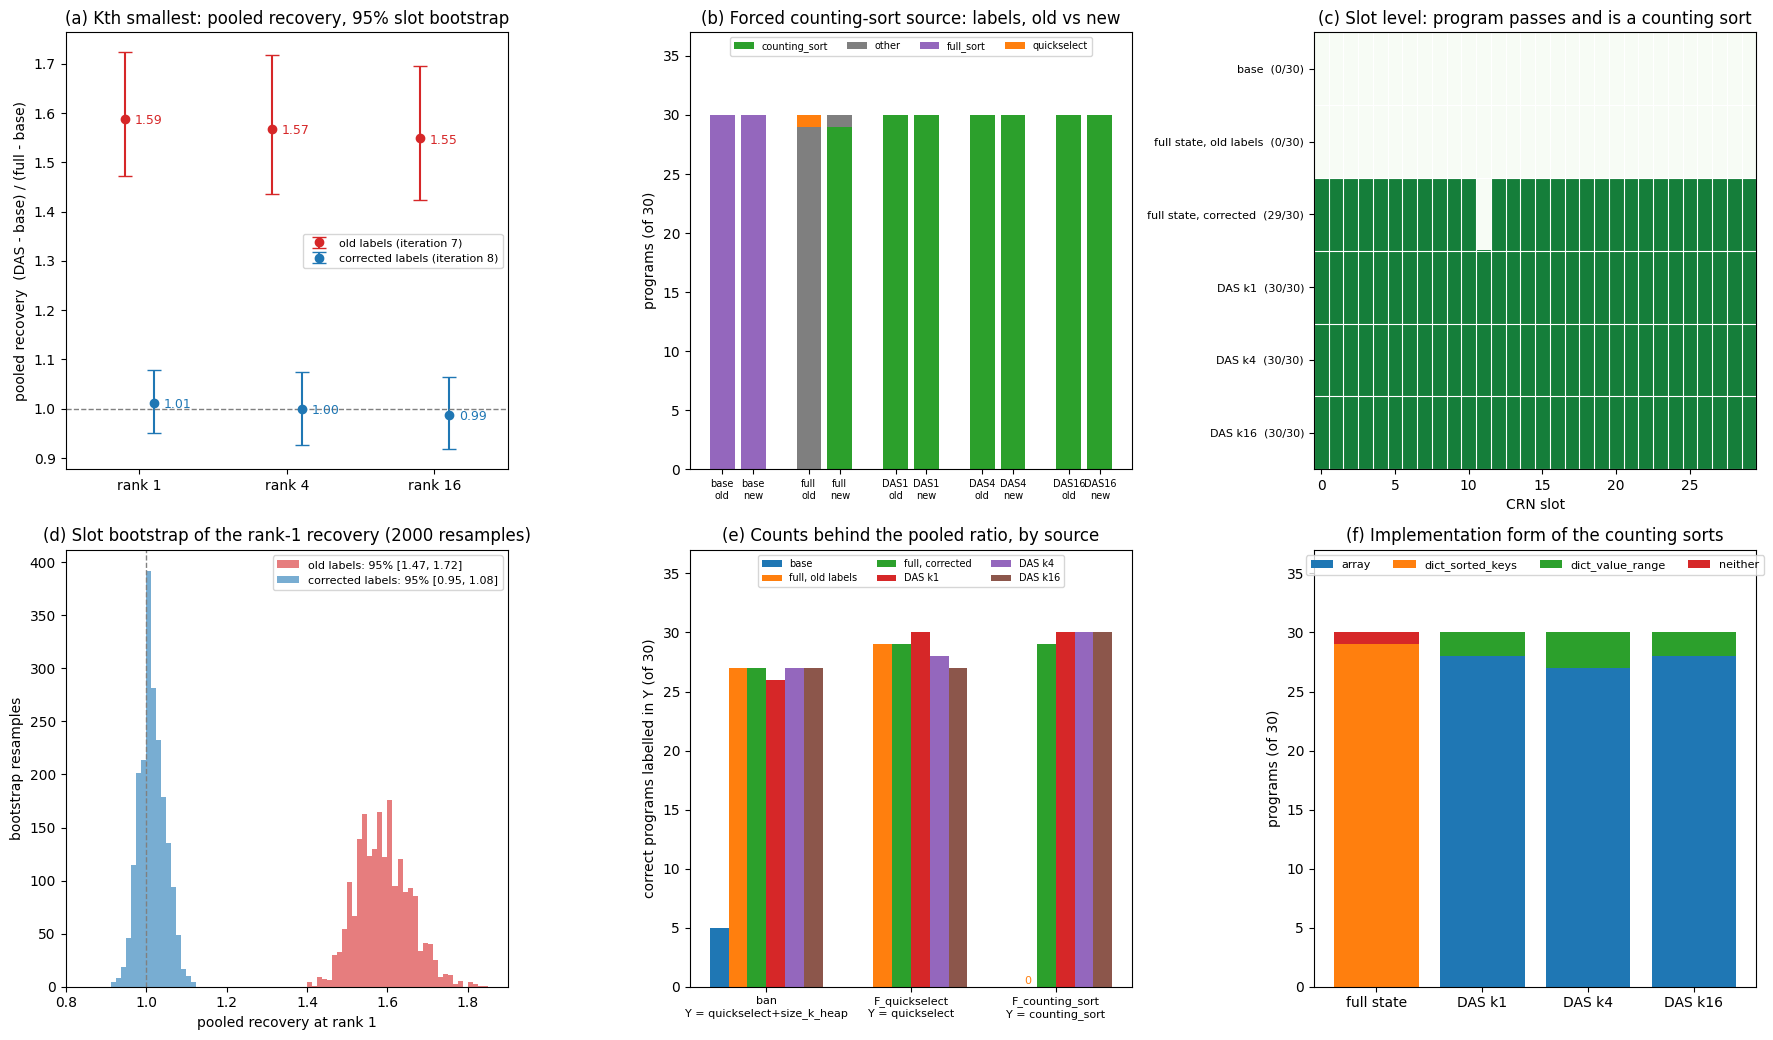

In [26]:
fig, axs = plt.subplots(2, 3, figsize=(18, 10.5))
ks_plot = [k for k in RANKS if new_k[k]["recovery"] is not None]  # kth smallest has DAS cells at ranks 1, 4 and 16
A_old, A_new = arms_of(T03_ROWS, "T03"), arms_of(T03_ROWS, "T03", final_labels)

# (a) pooled recovery by rank, old vs corrected labels
ax = axs[0, 0]
x = np.arange(len(ks_plot))
for off, per_k, name, col in ((-0.1, old_k, "old labels (iteration 7)", "tab:red"),
                              (0.1, new_k, "corrected labels (iteration 8)", "tab:blue")):
    y = np.array([per_k[k]["recovery"] for k in ks_plot])
    lo = y - np.array([per_k[k]["recovery_ci"][0] for k in ks_plot])
    hi = np.array([per_k[k]["recovery_ci"][1] for k in ks_plot]) - y
    ax.errorbar(x + off, y, yerr=[lo, hi], fmt="o", capsize=5, color=col, label=name)
    for xi, yi in zip(x + off, y):
        ax.annotate(f"{yi:.2f}", (xi, yi), xytext=(7, -4), textcoords="offset points", color=col, fontsize=9)
ax.axhline(1.0, ls="--", color="grey", lw=1)
ax.set_xticks(x, [f"rank {k}" for k in ks_plot])
ax.set_xlim(-0.5, len(ks_plot) - 0.5)
ax.set_ylabel("pooled recovery  (DAS - base) / (full - base)")
ax.set_title("(a) Kth smallest: pooled recovery, 95% slot bootstrap")
ax.legend(loc="center right", fontsize=8)

# (b) where the forced counting-sort source's programs land, old vs corrected labels
ax = axs[0, 1]
arms_b = [("BASE_PAD", "base"), ("FULL_F_counting_sort", "full"), ("DASLY_F_counting_sort_k1", "DAS1"),
          ("DASLY_F_counting_sort_k4", "DAS4"), ("DASLY_F_counting_sort_k16", "DAS16")]
groups = []
for arm, short in arms_b:
    rs = [r for r in T03_ROWS if r["arm"] == arm]
    groups.append((f"{short}\nold", Counter(r["label"] if r["passed"] else "fails tests" for r in rs)))
    groups.append((f"{short}\nnew", Counter(final_labels[r["sample_id"]] if r["passed"] else "fails tests" for r in rs)))
cats = sorted({c for _, cnt in groups for c in cnt}, key=lambda c: (c == "fails tests", c != "counting_sort", c != "other", c))
palette = {"counting_sort": "tab:green", "other": "tab:grey", "full_sort": "tab:purple", "quickselect": "tab:orange",
           "fails tests": "black"}
xb = np.array([i + (i // 2) * 0.8 for i in range(len(groups))])
bottom = np.zeros(len(groups))
for c in cats:
    h = np.array([cnt.get(c, 0) for _, cnt in groups])
    ax.bar(xb, h, bottom=bottom, width=0.8, label=c, color=palette.get(c))
    bottom += h
ax.set_xticks(xb, [g for g, _ in groups], fontsize=7)
ax.set_ylim(0, 37)
ax.set_ylabel("programs (of 30)")
ax.set_title("(b) Forced counting-sort source: labels, old vs new")
ax.legend(fontsize=7, loc="upper center", ncol=len(cats))

# (c) the slot-level data behind the bootstrap: passes and is a counting sort, per CRN slot
ax = axs[0, 2]
rows_c = [("BASE_PAD", "base", A_old), ("FULL_F_counting_sort", "full state, old labels", A_old),
          ("FULL_F_counting_sort", "full state, corrected", A_new), ("DASLY_F_counting_sort_k1", "DAS k1", A_new),
          ("DASLY_F_counting_sort_k4", "DAS k4", A_new), ("DASLY_F_counting_sort_k16", "DAS k16", A_new)]
grid = np.array([vec(A, arm, ["counting_sort"]) for arm, _, A in rows_c])
ax.imshow(grid, cmap="Greens", aspect="auto", vmin=0, vmax=1.25)
ax.set_yticks(range(len(rows_c)), [f"{name}  ({int(g.sum())}/30)" for (_, name, _), g in zip(rows_c, grid)], fontsize=8)
ax.set_xticks(range(0, N, 5))
ax.set_xticks(np.arange(-0.5, N, 1), minor=True)
ax.set_yticks(np.arange(-0.5, len(rows_c), 1), minor=True)
ax.grid(which="minor", color="white", lw=0.8)
ax.tick_params(which="minor", length=0)
ax.set_xlabel("CRN slot")
ax.set_title("(c) Slot level: program passes and is a counting sort")

# (d) bootstrap distribution of the rank-1 pooled recovery (the same resamples as boot_ci)
ax = axs[1, 0]
srcs = sources("T03")
for name, A, col in (("old labels", A_old, "tab:red"), ("corrected labels", A_new, "tab:blue")):
    rng = np.random.default_rng(SEED)
    vals = []
    for _ in range(BOOT):
        r, _, _ = pooled_recovery(A, srcs, 1, rng.integers(0, N, N), "das")
        if r is not None:
            vals.append(r)
    ax.hist(vals, bins=np.linspace(0.85, 1.85, 81), alpha=0.6, color=col, label=f"{name}: 95% [{np.percentile(vals, 2.5):.2f}, {np.percentile(vals, 97.5):.2f}]")
ax.axvline(1.0, ls="--", color="grey", lw=1)
ax.set_xlabel("pooled recovery at rank 1")
ax.set_ylabel("bootstrap resamples")
ax.set_title(f"(d) Slot bootstrap of the rank-1 recovery ({BOOT} resamples)")
ax.legend(fontsize=8)

# (e) the counts behind the ratio, per source
ax = axs[1, 1]
ps_old, ps_new = a5["old"]["T03"]["per_source"], a5["new"]["T03"]["per_source"]
src_names = list(ps_new)
bars = [("base", lambda s: ps_new[s]["base_count"]), ("full, old labels", lambda s: ps_old[s]["full_count"]),
        ("full, corrected", lambda s: ps_new[s]["full_count"])] + \
       [(f"DAS k{k}", (lambda k: lambda s: ps_new[s]["das"].get(k, {}).get("count", 0))(k)) for k in (1, 4, 16)]
wb = 0.13
for i, (bn, get) in enumerate(bars):
    hs = [get(s) for s in src_names]
    ax.bar(np.arange(len(src_names)) + (i - 2.5) * wb, hs, width=wb, label=bn)
    if bn == "full, old labels":  # mark the zero that drove the old ratio
        for j, hv in enumerate(hs):
            if hv == 0:
                ax.annotate("0", (j + (i - 2.5) * wb, 0), xytext=(0, 2), textcoords="offset points", ha="center", fontsize=8, color="tab:orange")
ax.set_xticks(np.arange(len(src_names)), [f"{s}\nY = {'+'.join(ps_new[s]['Y'])}" for s in src_names], fontsize=8)
ax.set_ylim(0, 37)
ax.set_ylabel("correct programs labelled in Y (of 30)")
ax.set_title("(e) Counts behind the pooled ratio, by source")
ax.legend(fontsize=7, ncol=3, loc="upper center")

# (f) implementation form of the counting sorts (regex on the program text, item 0a)
ax = axs[1, 2]
forms = items["0a"]["summary"]["forms"]
arms_f = ["FULL_F_counting_sort", "DASLY_F_counting_sort_k1", "DASLY_F_counting_sort_k4", "DASLY_F_counting_sort_k16"]
bottom = np.zeros(len(arms_f))
for c in ("array", "dict_sorted_keys", "dict_value_range", "neither"):
    h = np.array([forms[a].get(c, 0) for a in arms_f])
    ax.bar(range(len(arms_f)), h, bottom=bottom, label=c)
    bottom += h
ax.set_xticks(range(len(arms_f)), ["full state", "DAS k1", "DAS k4", "DAS k16"])
ax.set_ylim(0, 37)
ax.set_ylabel("programs (of 30)")
ax.set_title("(f) Implementation form of the counting sorts")
ax.legend(fontsize=8, ncol=4, loc="upper center")

plt.tight_layout()
plt.show()

## What this shows, and what was not run here

- **The correction.** Once dictionary-form counting sort is labelled `counting_sort`, the full-state exchange of the forced counting-sort source gives 29/30 instead of 0/30. The denominator of the pooled ratio rises from 51 to 80, and kth-smallest recovery falls from about 1.6 to about 1.0. A rank-1 DAS subspace therefore carries roughly the whole effect of the full-state swap, not 1.6 times it. Figure (f) adds the routing correction: on kth smallest the subspace edit changes the *form* of the counting sort (an array of counts instead of a dictionary), not the algorithm. The labeller was validated before the relabel (references 6/6, gold kappa unchanged at 0.951, controls 5/5). The headline numbers are re-derived through an independent regex path, whose placebos fail as required.
- **Not run in this notebook.** Items 0b–0k, `s0`, `apply`, and the `audit/rederive.py` re-derivation read six more iteration-7 artifacts and the 1.3 MB report. The full run (`uv sync && uv run eval.py --stages all`, about 25 s with the judge cache present) applies all 84 report edits and cuts the residual-claim lint from 35 hits to 0. Its stdlib audit re-derives 97 values with 0 mismatches, with 6/6 placebos failing as required.
- **Not run in the original either** (stated in its record): the Gemma dormancy checks, the Qwen untrained network beyond shortest path, and a prefill-matched instruction cell.
- **Scale.** The only tunable is `BOOT`. 2000 is the original setting, and the whole notebook runs in well under a minute on a CPU.